# Company Bankruptcy

Data from the Taiwan Economic Journal for the years 1999-2009 representing company bankruptcy based on the business regulations of the Taiwan Stock Exchange

## Introduction

In this kernal we will use various predictive models to see how accurate they are in detecting whether we can correctly predict which companies will face bankruptcy in the future. As described in the data section, the dataset contains:
- 95 features (X1-X95, business regulations of Taiwan Stock Exchange)
- 1 Vector of labels

Our aim in this project is to use these features to understand their impact / role on the selected models and how they can help us recognize the companies that are close to bankruptcy

In [3]:
#%pip install -U pip wheel
#%pip install -U catboost

  Using cached pip-25.2-py3-none-any.whl.metadata (4.7 kB)
  Using cached wheel-0.45.1-py3-none-any.whl.metadata (2.3 kB)
Using cached pip-25.2-py3-none-any.whl (1.8 MB)
Using cached wheel-0.45.1-py3-none-any.whl (72 kB)
  Attempting uninstall: wheel
    Found existing installation: wheel 0.43.0
    Uninstalling wheel-0.43.0:
      Successfully uninstalled wheel-0.43.0
  Attempting uninstall: pip
    Found existing installation: pip 24.0
    Uninstalling pip-24.0:
      Successfully uninstalled pip-24.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow-macos 2.16.2 requires tensorflow==2.16.2; platform_system == "Darwin" and platform_machine == "arm64", but you have tensorflow 2.19.0 which is incompatible.
Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 1.3 MB/s  0:00:21m0:00:01

In [7]:
#%pip install -U mlxtend

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 1.1 MB/s  0:00:01 eta 0:00:010m
Note: you may need to restart the kernel to use updated packages.


In [1]:
# IMPORTING LIBRARIES

# General Libraries

import os
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import norm
from collections import Counter
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings(action="ignore")

# Preprocessing Libraries

from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedShuffleSplit

# Machine Learning Libraries

import sklearn
import xgboost as xgb
from sklearn import tree
from sklearn.svm import SVC
from sklearn.metrics import roc_curve
from imblearn.pipeline import Pipeline
from catboost import CatBoostClassifier
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import StackingClassifier
from sklearn.metrics import classification_report
from mlxtend.classifier import StackingCVClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import recall_score, f1_score, roc_auc_score
from imblearn.pipeline import make_pipeline as imbalanced_make_pipeline
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score

In [3]:
# IMPORTING DATA
band_data_file_path = "/Users/scottkeighley/Desktop/MSDS_422/Company Bankruptcy Prediction/data.csv"
bank_data = pd.read_csv(band_data_file_path)
bank_data.head()

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490


In [7]:
bank_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6819 entries, 0 to 6818
Data columns (total 96 columns):
 #   Column                                                    Non-Null Count  Dtype  
---  ------                                                    --------------  -----  
 0   Bankrupt?                                                 6819 non-null   int64  
 1    ROA(C) before interest and depreciation before interest  6819 non-null   float64
 2    ROA(A) before interest and % after tax                   6819 non-null   float64
 3    ROA(B) before interest and depreciation after tax        6819 non-null   float64
 4    Operating Gross Margin                                   6819 non-null   float64
 5    Realized Sales Gross Margin                              6819 non-null   float64
 6    Operating Profit Rate                                    6819 non-null   float64
 7    Pre-tax net Interest Rate                                6819 non-null   float64
 8    After-tax net Int

Now that we have an idea of our data, we need to obtain more information. The first thing we want to understand is the nature of our data, namely if the data are numerical or categorical and if we have missing information among them. It is possible to check both these points using the .info() pandas method

The resulting panel is informative for us: 
- The dataset is composed of a combination of 6819 observations per each of our 96 features
- All of the features are numerical (int64 or float64)
- There are no missing values (Nan) among the data

Considering that all our features are numeric, we can easily calculate their descriptive statistics

In [9]:
# Computing the descriptive statistics of our numerical features

bank_data.describe()

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
count,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,...,6819.000000,6.819000e+03,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.0,6819.000000
mean,0.032263,0.505180,0.558625,0.553589,0.607948,0.607929,0.998755,0.797190,0.809084,0.303623,...,0.807760,1.862942e+07,0.623915,0.607946,0.840402,0.280365,0.027541,0.565358,1.0,0.047578
std,0.176710,0.060686,0.065620,0.061595,0.016934,0.016916,0.013010,0.012869,0.013601,0.011163,...,0.040332,3.764501e+08,0.012290,0.016934,0.014523,0.014463,0.015668,0.013214,0.0,0.050014
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0,0.000000
25%,0.000000,0.476527,0.535543,0.527277,0.600445,0.600434,0.998969,0.797386,0.809312,0.303466,...,0.796750,9.036205e-04,0.623636,0.600443,0.840115,0.276944,0.026791,0.565158,1.0,0.024477
50%,0.000000,0.502706,0.559802,0.552278,0.605997,0.605976,0.999022,0.797464,0.809375,0.303525,...,0.810619,2.085213e-03,0.623879,0.605998,0.841179,0.278778,0.026808,0.565252,1.0,0.033798
75%,0.000000,0.535563,0.589157,0.584105,0.613914,0.613842,0.999095,0.797579,0.809469,0.303585,...,0.826455,5.269777e-03,0.624168,0.613913,0.842357,0.281449,0.026913,0.565725,1.0,0.052838
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,9.820000e+09,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,1.000000


Despite the fact that we already know that there are no missing values it is important to computationally check that this is true, to avoid errors and time wasted in the following steps

In [13]:
# Checking Nan presence

[print(col) for col in bank_data if bank_data[col].isna().sum() > 0]

[]

A further consideration needs to be done given the possibility we have duplicates in our data. Duplicates are identical observations that can create redundancy in our data and need to be dropped.

In [15]:
# Checking for duplicates

bank_data.duplicated().sum()

0

Considering the project task, and now that we have a general overview of our data, we need to focus our attention on the labels: which are the financially stable and unstable companies?

In [17]:
# The classes are heavily skewed, we need to solve this issue later

print(bank_data['Bankrupt?'].value_counts())
print('-'* 30)
print('Financially stable: ', round(bank_data['Bankrupt?'].value_counts()[0]/len(bank_data) * 100,2), '% of the dataset')
print('Financially unstable: ', round(bank_data['Bankrupt?'].value_counts()[1]/len(bank_data) * 100,2), '% of the dataset')

Bankrupt?
0    6599
1     220
Name: count, dtype: int64
------------------------------
Financially stable:  96.77 % of the dataset
Financially unstable:  3.23 % of the dataset


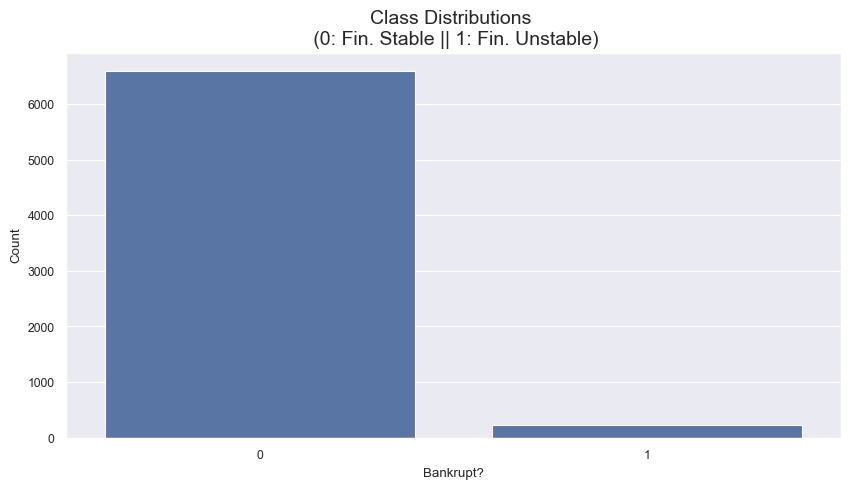

In [22]:
# Checking labels distributions

plt.figure(figsize=(10,5))
ax = sns.countplot(x='Bankrupt?', data=bank_data, order=[0,1])
ax.set_title('Class Distributions \n (0: Fin. Stable || 1: Fin. Unstable)', fontsize=14)
ax.set_xlabel('Bankrupt?'); ax.set_ylabel('Count')
plt.show()

Looking at the plot above we can clearly see how our labels are strongly unbalanced. This is the main obstacle that we need to solve to obtain good performance

## EDA

Let's explore our dataset to gain as much information as possible from several types of visualizations. A first general plot to show is the correlation heatmap that plots all the correlations (linear and non-linear, depending on the selected test: Pearson or Spearman) among numerical variables of the dataset. Knowing the correlation among features is an important step in deciding which features to maintain during training. 

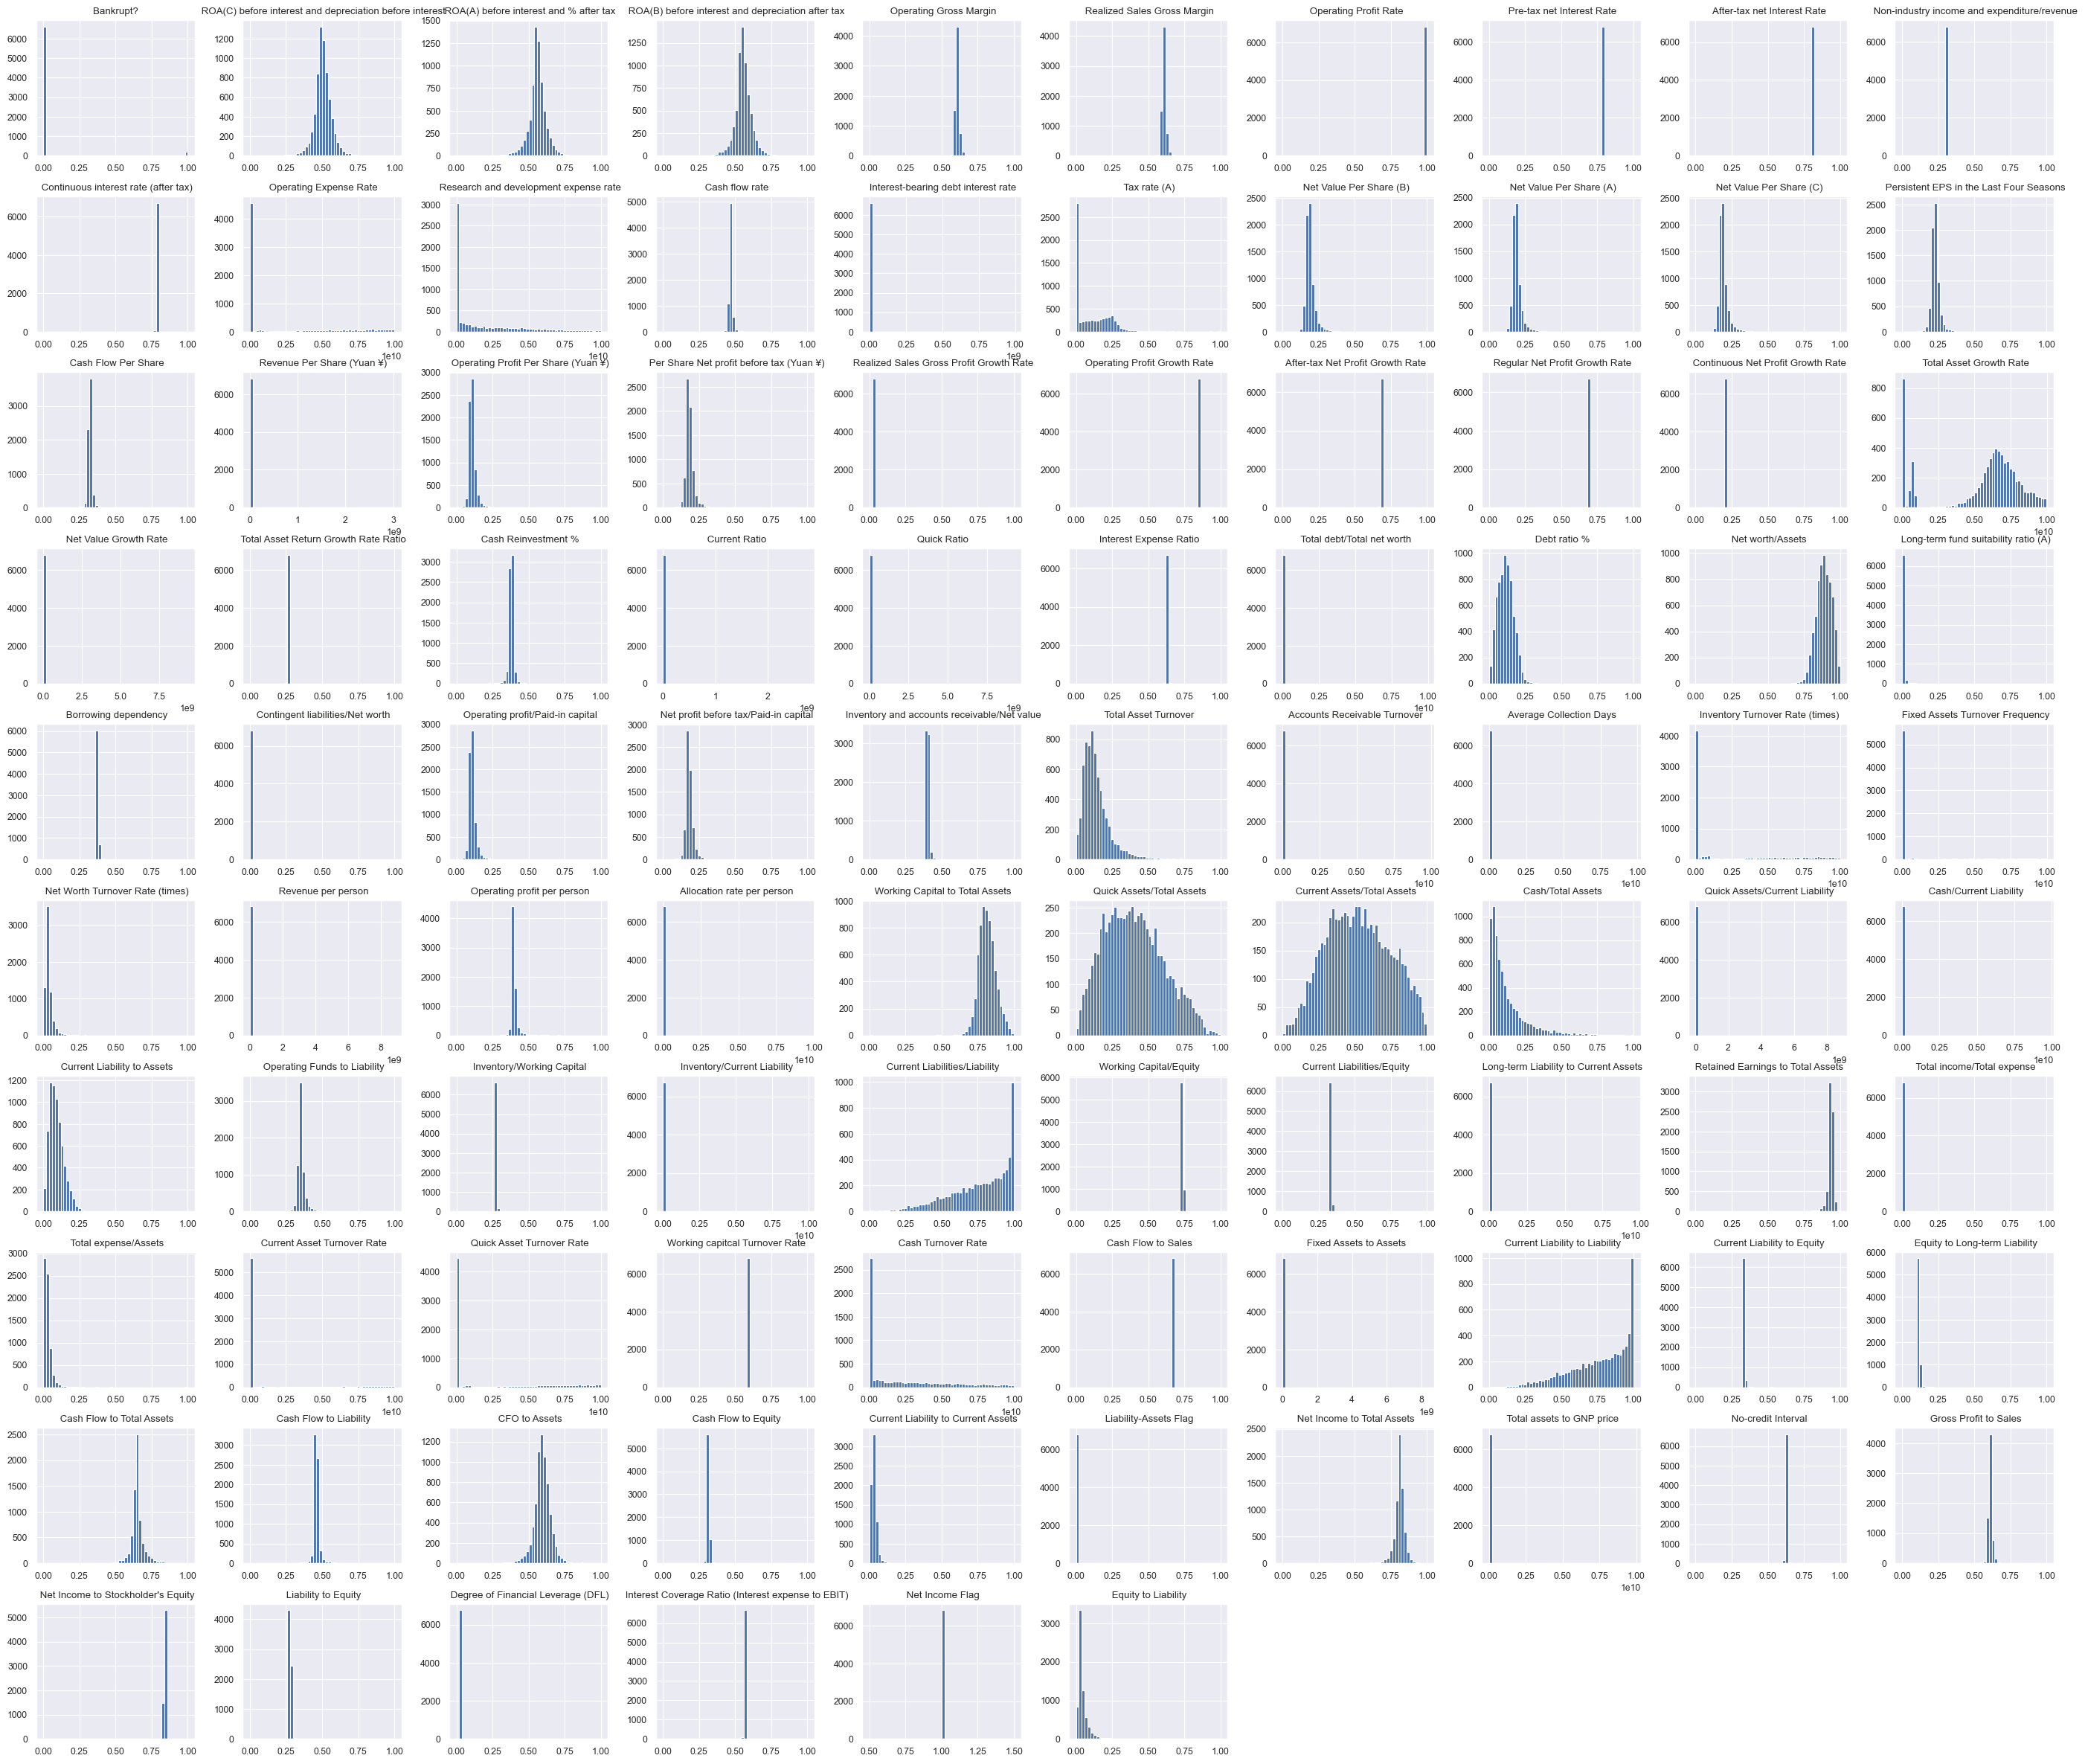

In [27]:
# Histograms of numerical data

bank_data.hist(figsize = (35,30), bins = 50)
plt.show()

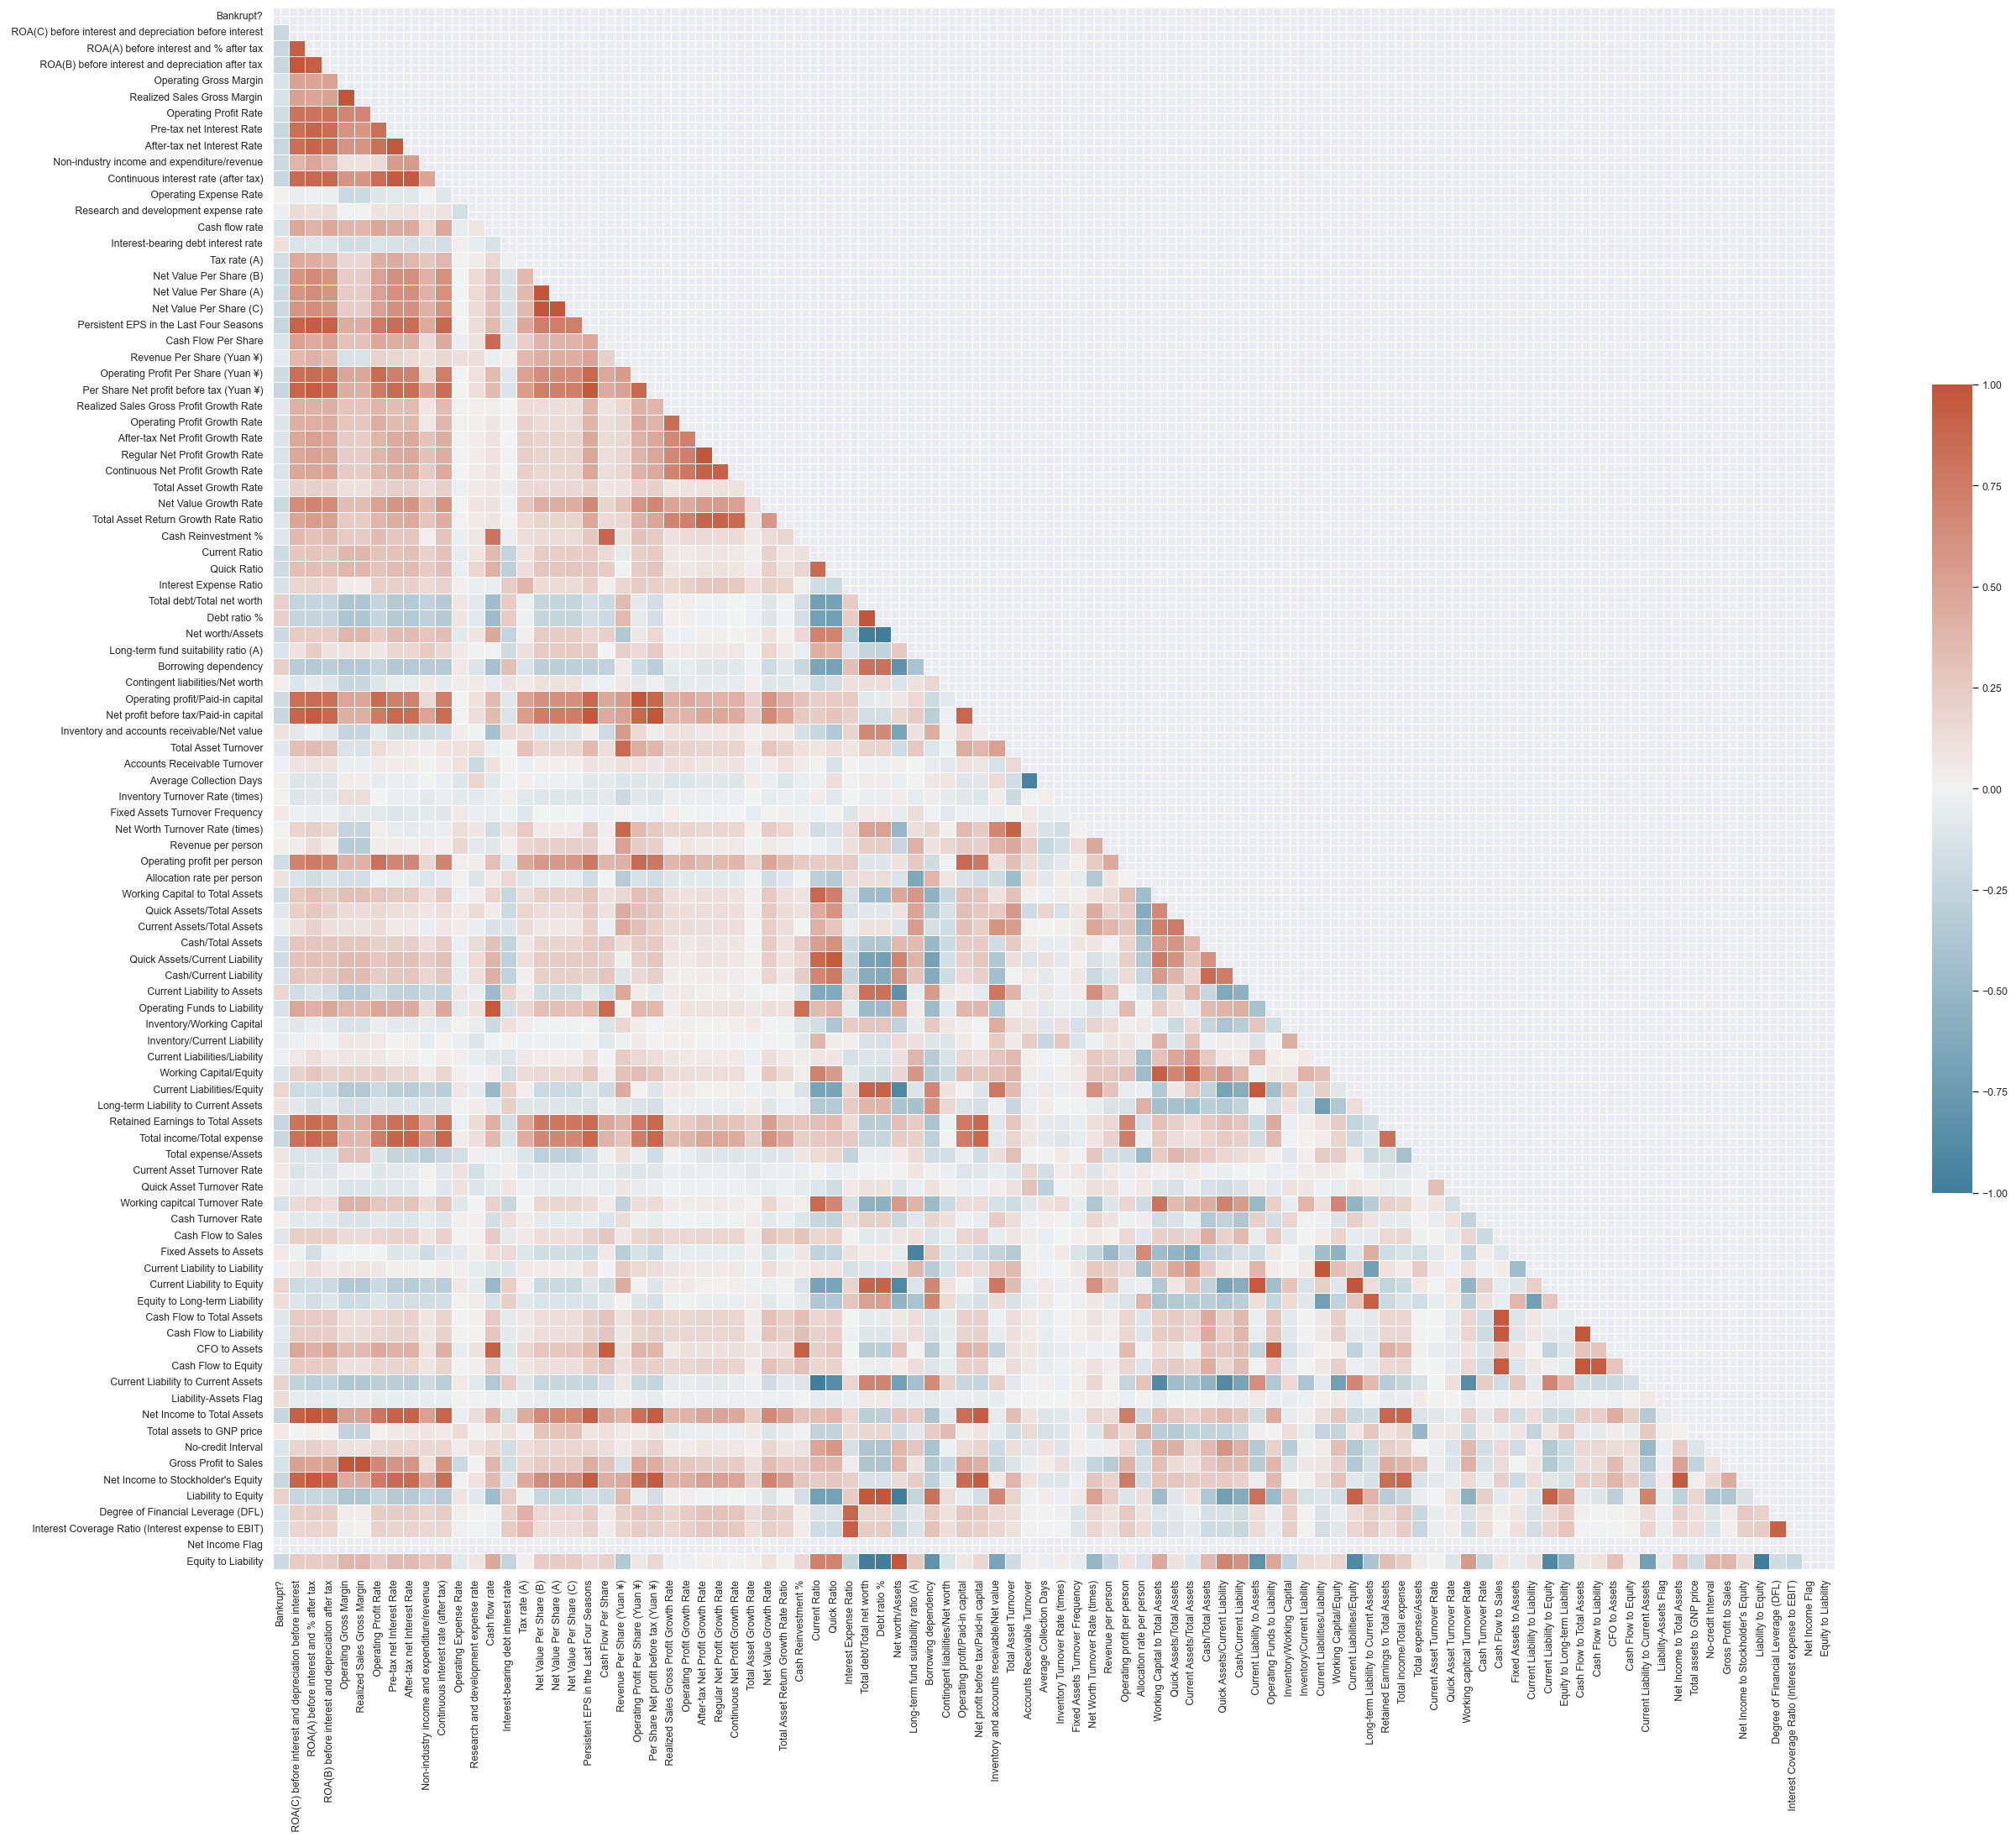

In [31]:
# EDA & VISUALIZATIONS

# Correlation Heatmap (Spearman)

f, ax = plt.subplots(figsize=(30, 25))
mat = bank_data.corr('spearman')
mask = np.triu(np.ones_like(mat, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)
sns.heatmap(mat, mask=mask, cmap=cmap, vmax=1, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})
plt.show()

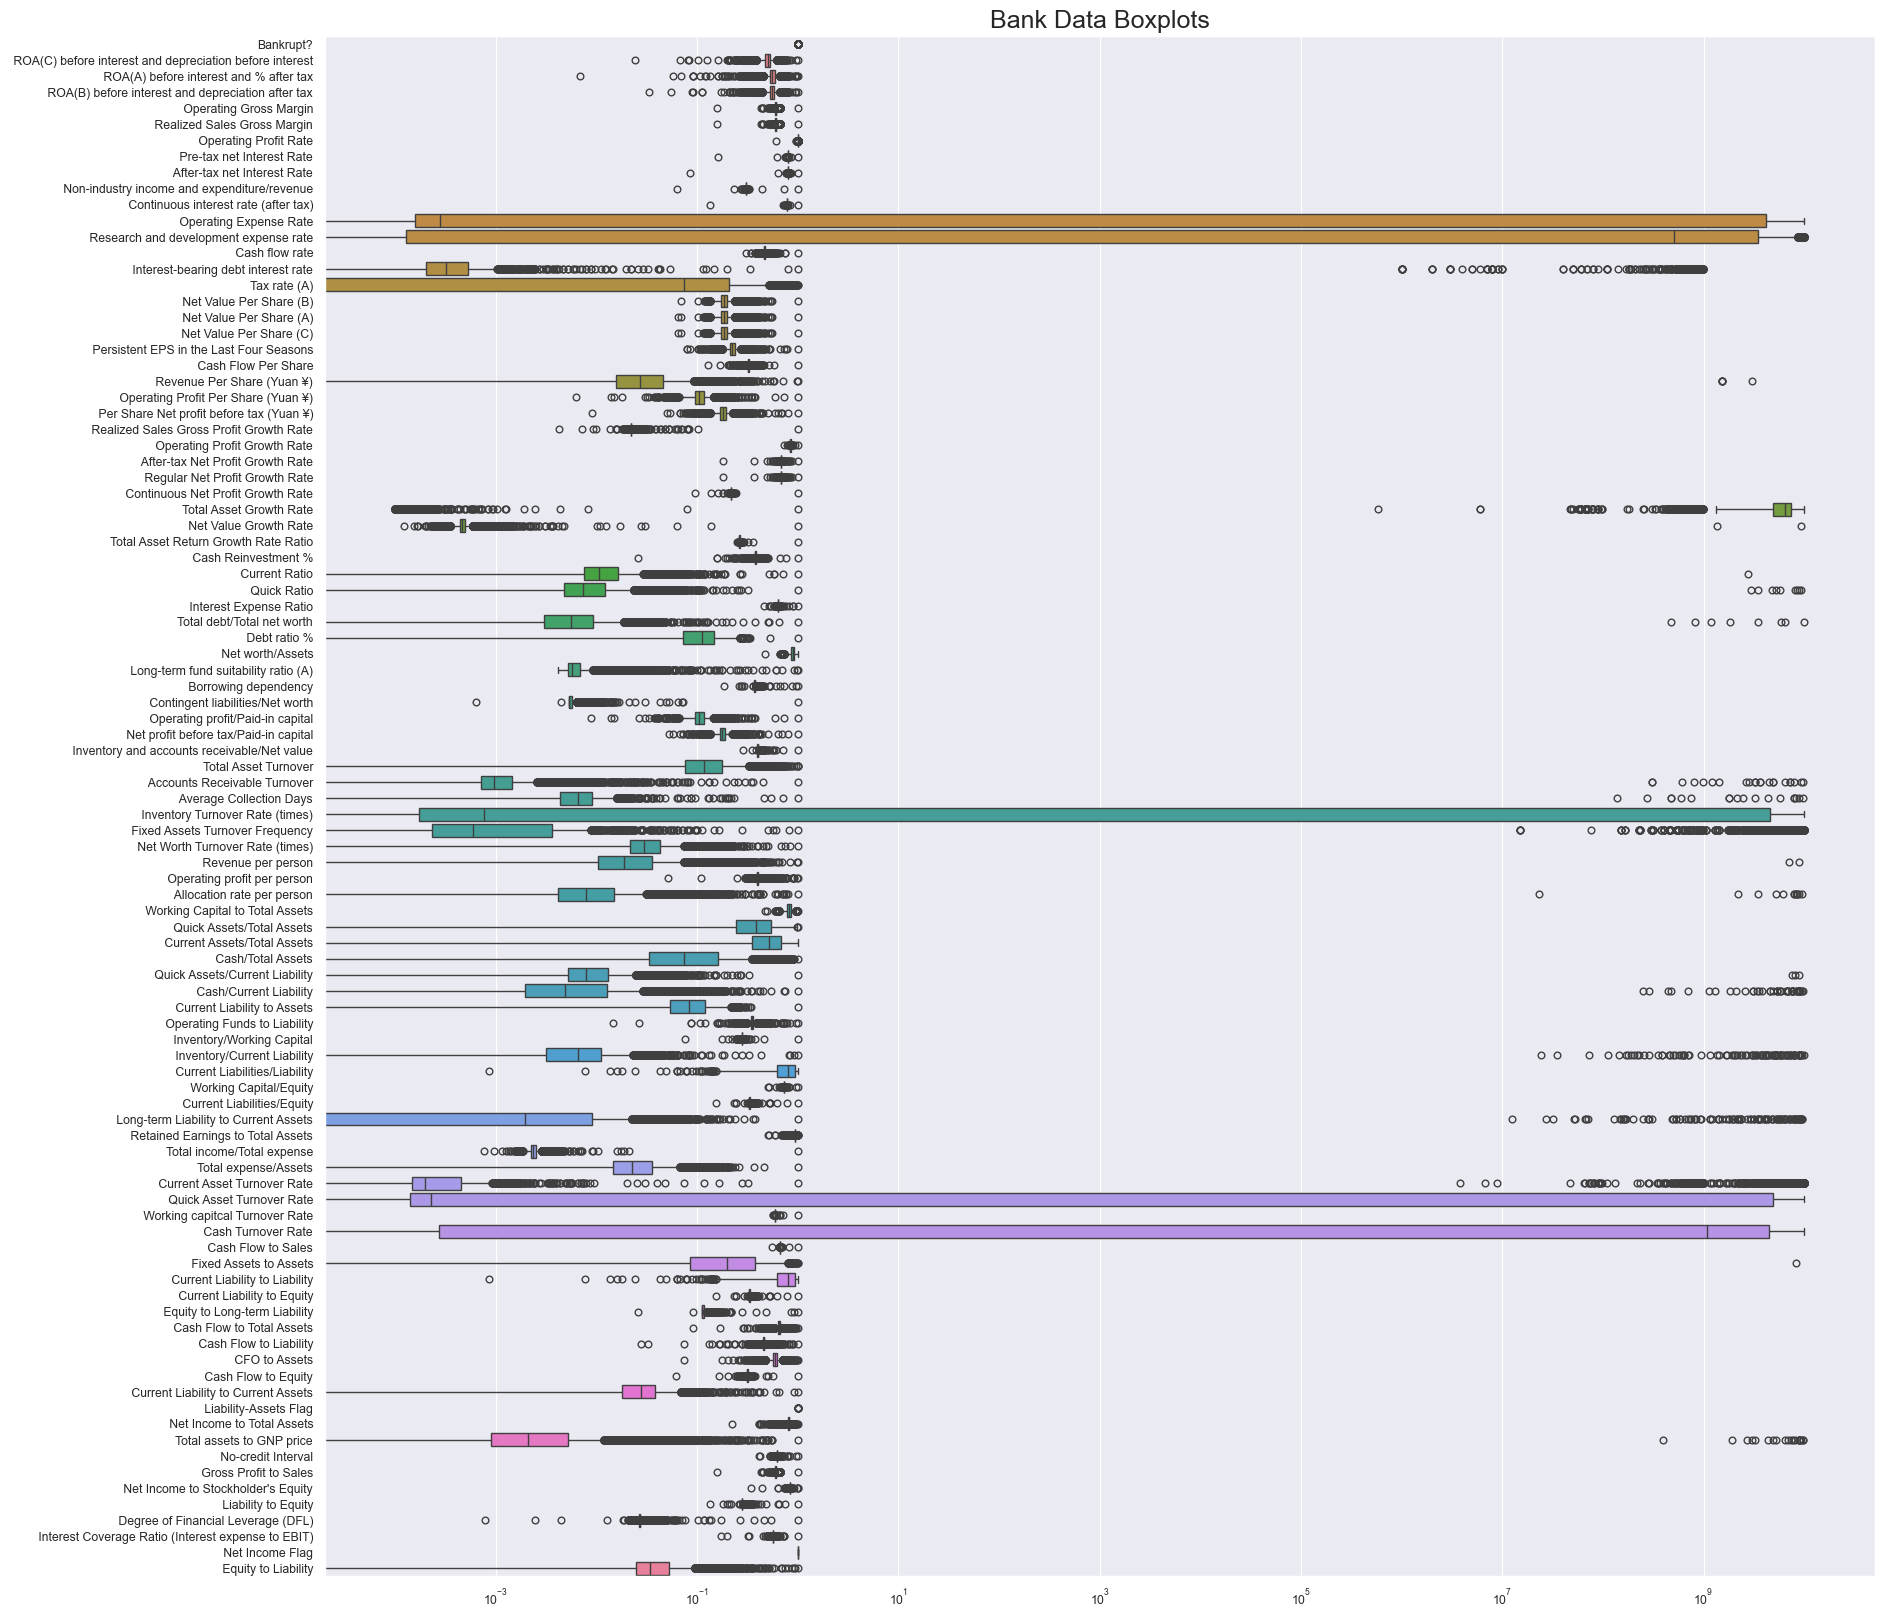

In [35]:
# Plotting boxplots of the numerical features

plt.figure(figsize = (20,20))
ax = sns.boxplot(data = bank_data, orient="h")
ax.set_title('Bank Data Boxplots', fontsize = 18)
ax.set(xscale="log")
plt.show()

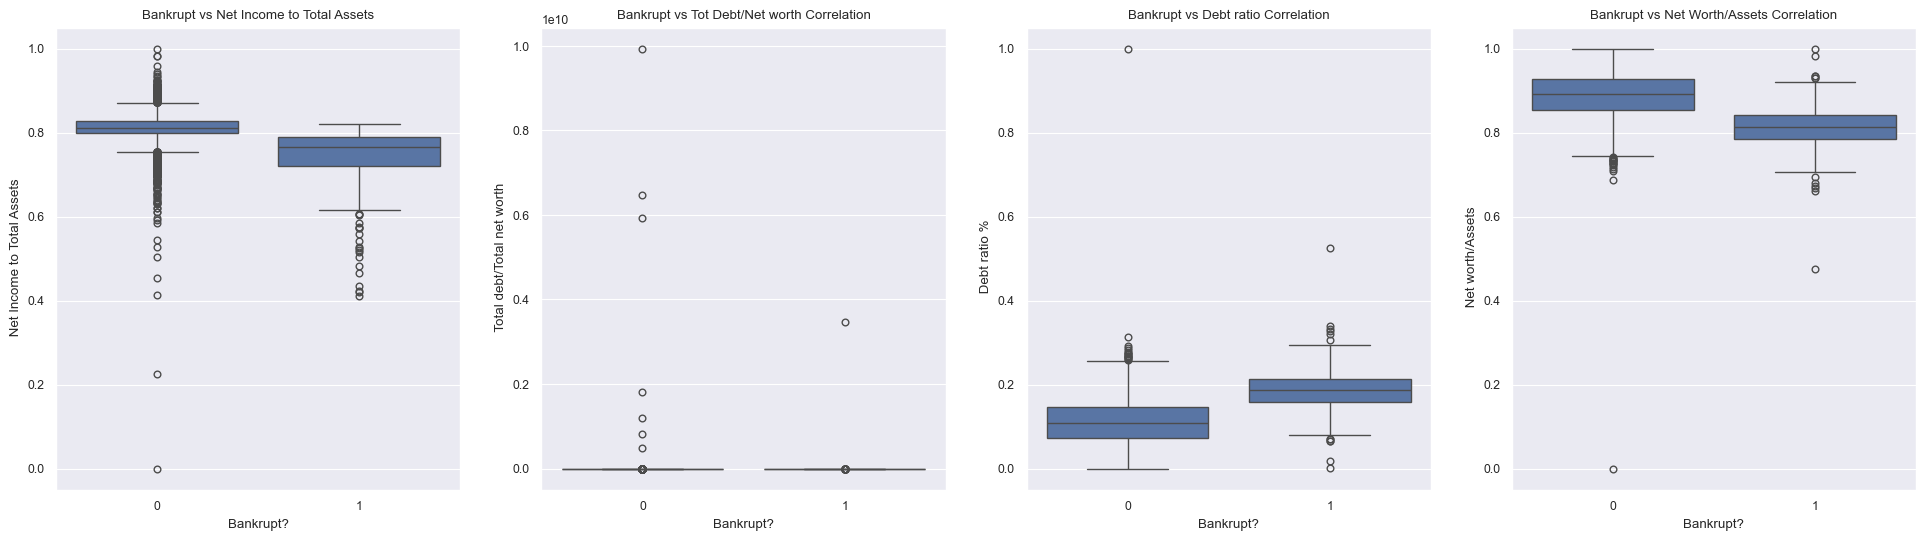

In [37]:
# Plotting interesting features

f, axes = plt.subplots(ncols=4, figsize=(24, 6))

sns.boxplot(x='Bankrupt?', y=" Net Income to Total Assets", data=bank_data, ax=axes[0])
axes[0].set_title('Bankrupt vs Net Income to Total Assets')

sns.boxplot(x='Bankrupt?', y=" Total debt/Total net worth", data=bank_data, ax=axes[1])
axes[1].set_title('Bankrupt vs Tot Debt/Net worth Correlation')

sns.boxplot(x='Bankrupt?', y=" Debt ratio %", data=bank_data, ax=axes[2])
axes[2].set_title('Bankrupt vs Debt ratio Correlation')

sns.boxplot(x='Bankrupt?', y=" Net worth/Assets", data=bank_data, ax=axes[3])
axes[3].set_title('Bankrupt vs Net Worth/Assets Correlation')

plt.show()

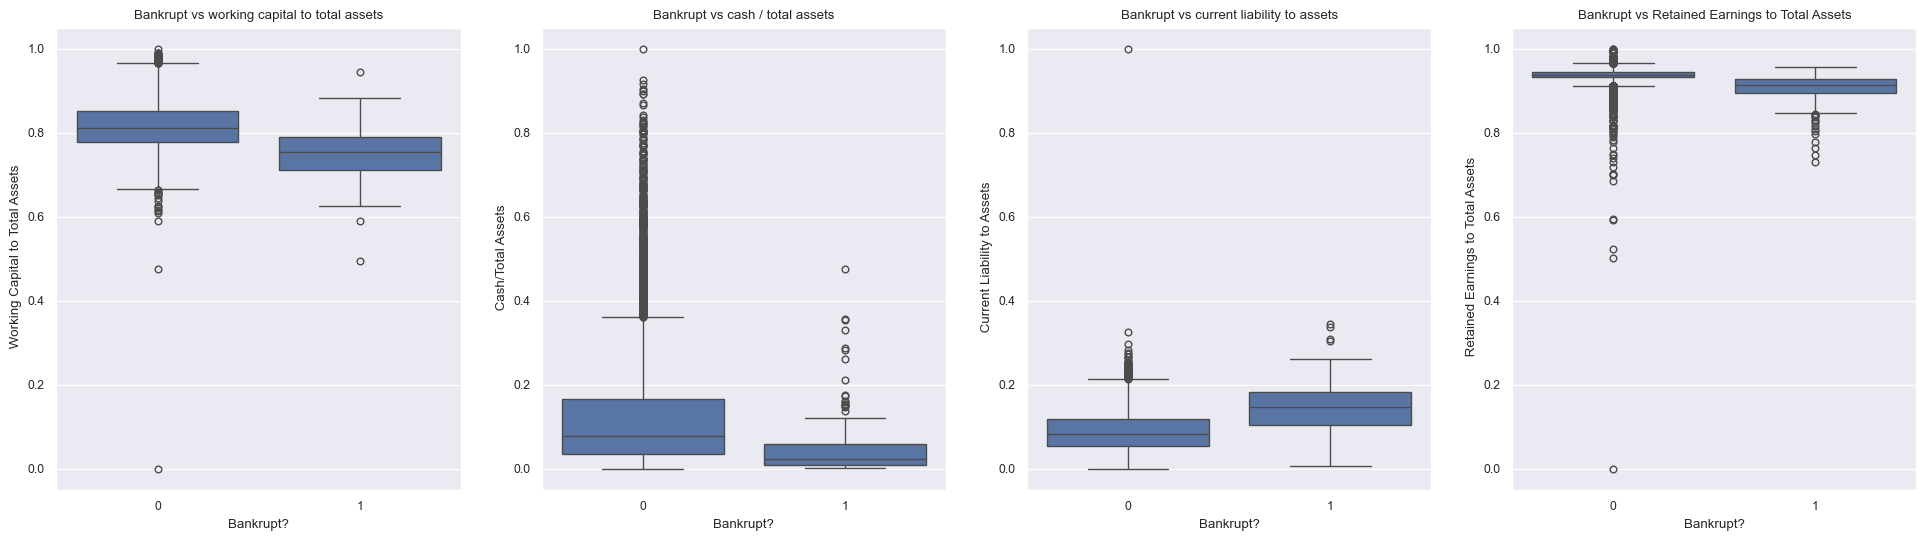

In [39]:
# Plotting other interesting features

f, axes = plt.subplots(ncols=4, figsize=(24,6))

sns.boxplot(x='Bankrupt?', y=" Working Capital to Total Assets", data=bank_data, ax=axes[0])
axes[0].set_title('Bankrupt vs working capital to total assets')

sns.boxplot(x='Bankrupt?', y=" Cash/Total Assets", data=bank_data, ax=axes[1])
axes[1].set_title('Bankrupt vs cash / total assets')

sns.boxplot(x='Bankrupt?', y=" Current Liability to Assets", data=bank_data, ax=axes[2])
axes[2].set_title('Bankrupt vs current liability to assets')

sns.boxplot(x='Bankrupt?', y=" Retained Earnings to Total Assets", data=bank_data, ax=axes[3])
axes[3].set_title('Bankrupt vs Retained Earnings to Total Assets')

plt.show()

Now, let's look at the distribution of these features for companies that are close to bankruptcy.

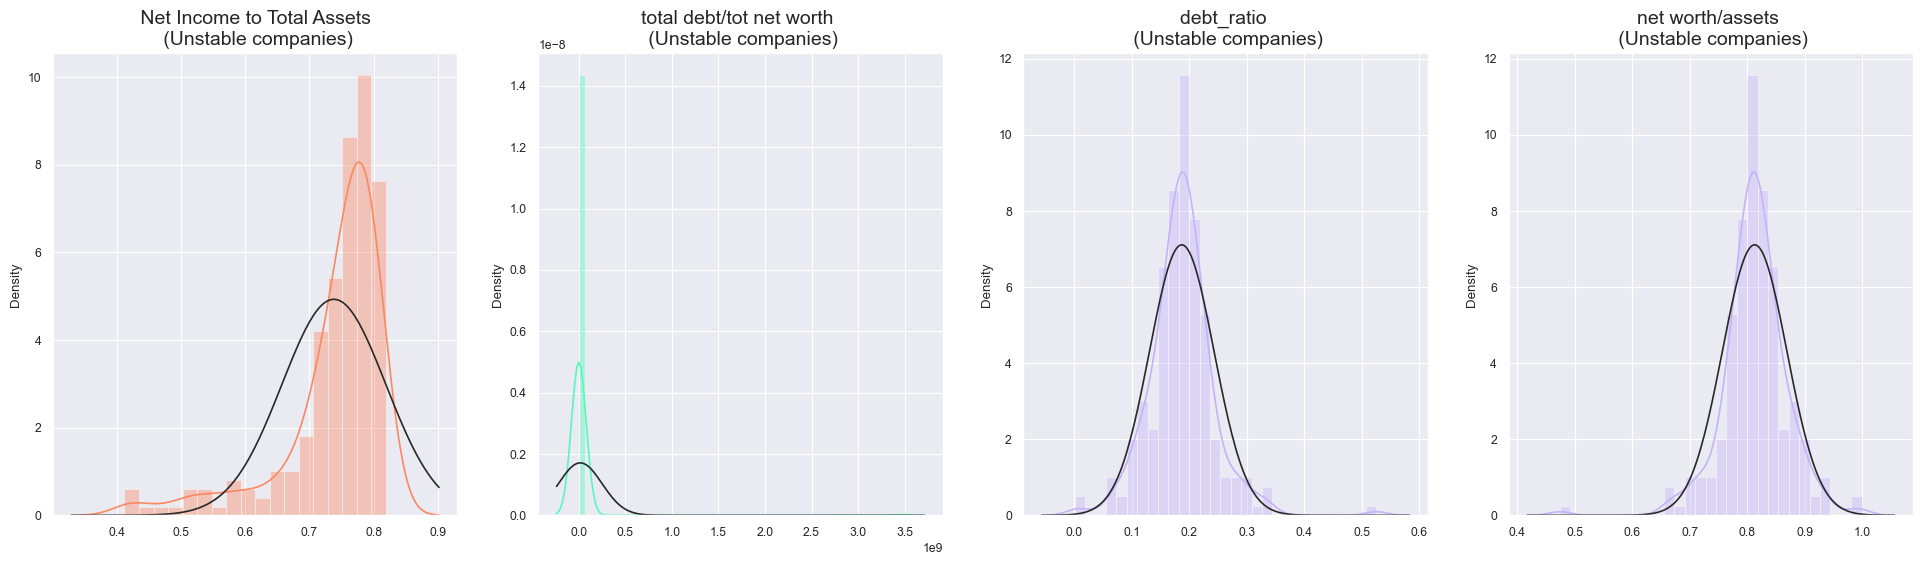

In [44]:
# Plotting the feature distributions for close to bankruptcy companies

f, (ax1, ax2, ax3, ax4) = plt.subplots(1,4, figsize=(24, 6))

cash_flow_rate = bank_data[' Net Income to Total Assets'].loc[bank_data['Bankrupt?'] == 1].values
sns.distplot(cash_flow_rate,ax=ax1, fit=norm, color='#FB8861')
ax1.set_title(' Net Income to Total Assets \n (Unstable companies)', fontsize=14)

tot_debt_net = bank_data[' Total debt/Total net worth'].loc[bank_data['Bankrupt?'] ==1].values
sns.distplot(tot_debt_net, ax=ax2, fit=norm, color='#56F9BB')
ax2.set_title('total debt/tot net worth \n (Unstable companies)', fontsize=14)

debt_ratio = bank_data[' Debt ratio %'].loc[bank_data['Bankrupt?'] == 1].values
sns.distplot(debt_ratio, ax=ax3, fit=norm, color='#C5B3F9')
ax3.set_title('debt_ratio \n (Unstable companies)', fontsize=14)

net_worth_assets = bank_data[' Net worth/Assets'].loc[bank_data['Bankrupt?'] == 1].values
sns.distplot(net_worth_assets, ax=ax4, fit=norm, color='#C5B3F9')
ax4.set_title('net worth/assets \n (Unstable companies)', fontsize=14)

plt.show()

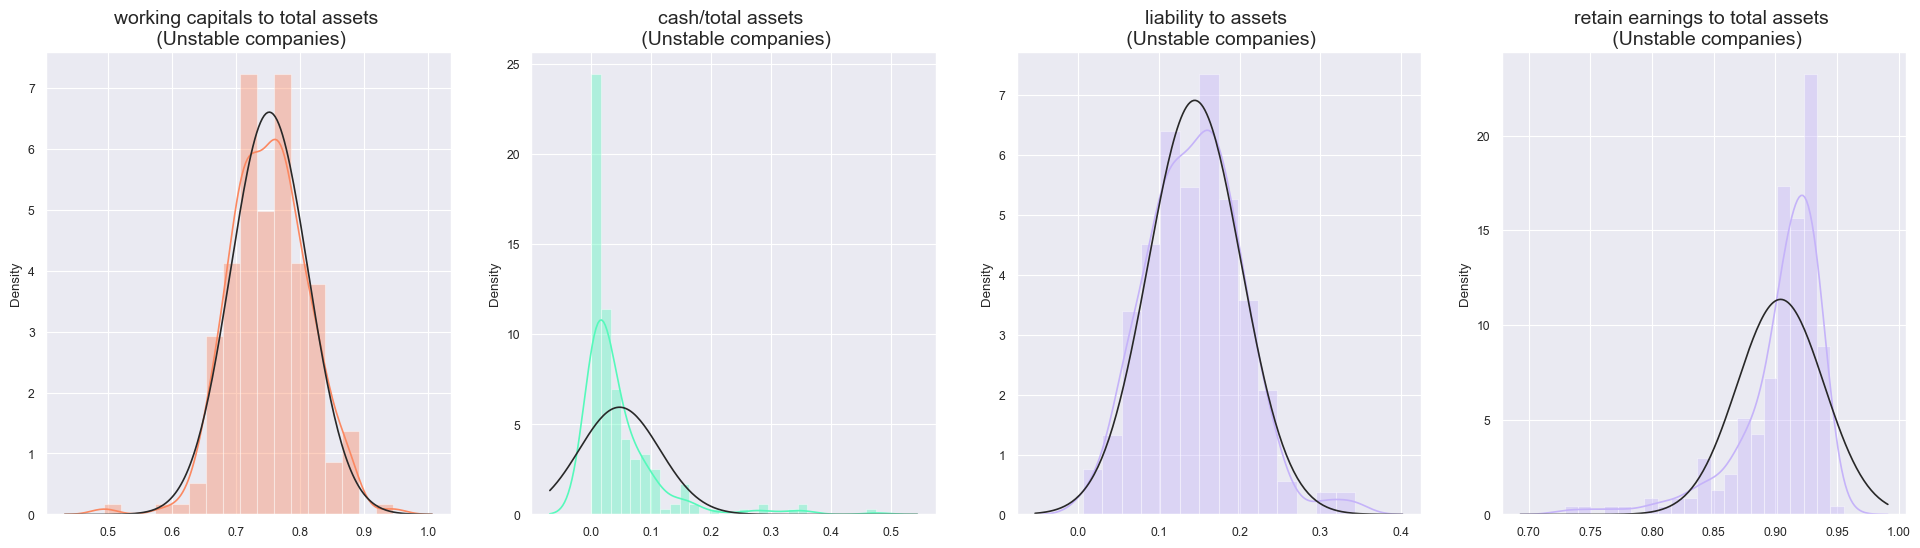

In [48]:
f, (ax1, ax2, ax3, ax4) = plt.subplots(1,4, figsize=(24, 6))

working_cap = bank_data[' Working Capital to Total Assets'].loc[bank_data['Bankrupt?'] == 1].values
sns.distplot(working_cap, ax=ax1, fit=norm, color='#FB8861')
ax1.set_title('working capitals to total assets \n (Unstable companies)', fontsize=14)

cash_tot_assets = bank_data[' Cash/Total Assets'].loc[bank_data['Bankrupt?'] == 1].values
sns.distplot(cash_tot_assets, ax=ax2, fit=norm, color='#56F9BB')
ax2.set_title('cash/total assets \n (Unstable companies)', fontsize=14)

asset_liab = bank_data[' Current Liability to Assets'].loc[bank_data['Bankrupt?'] == 1].values
sns.distplot(asset_liab, ax=ax3, fit=norm, color='#C5B3F9')
ax3.set_title('liability to assets \n (Unstable companies)', fontsize=14)

operating_funds = bank_data[' Retained Earnings to Total Assets'].loc[bank_data['Bankrupt?'] == 1].values
sns.distplot(operating_funds, ax=ax4, fit=norm, color='#C5B3F9')
ax4.set_title('retain earnings to total assets \n (Unstable companies)', fontsize=14)

plt.show()

## Outliers Removal

In this part of the project, we will try to remove the most extreme outliers (note that we can also impute them with the mean or the median instead of removing them). This should increase our model's performance.

In [51]:
# Outliers removal

def outliers_removal(feature, feature_name, dataset):

    # Identify 25th and 75th quartiles

    q25, q75 = np.percentile(feature, 25), np.percentile(feature, 75)
    print('Quartile 25: {} | Quartile 75: {}'.format(q25, q75))
    feat_iqr = q75 - q25
    print('iqr: {}'.format(feat_iqr))

    feat_cut_off = feat_iqr * 1.5
    feat_lower, feat_upper = q25 - feat_cut_off, q75 + feat_cut_off
    print('Cut Off: {}'.format(feat_cut_off))
    print(feature_name +' Lower: {}'.format(feat_lower))
    print(feature_name +' Upper: {}'.format(feat_upper))

    outliers = [x for x in feature if x < feat_lower or x > feat_upper]
    print(feature_name +' outliers for close to bankruptcy cases: {}'.format(len(outliers)))

    dataset = dataset.drop(dataset[(dataset[feature_name] > feat_upper) | (dataset[feature_name] < feat_lower)].index)
    print('-' * 65)

    return dataset

for col in bank_data:
    new_df = outliers_removal(bank_data[col], str(col), bank_data)

Quartile 25: 0.0 | Quartile 75: 0.0
iqr: 0.0
Cut Off: 0.0
Bankrupt? Lower: 0.0
Bankrupt? Upper: 0.0
Bankrupt? outliers for close to bankruptcy cases: 220
-----------------------------------------------------------------
Quartile 25: 0.476527080388047 | Quartile 75: 0.535562813825379
iqr: 0.05903573343733198
Cut Off: 0.08855360015599797
 ROA(C) before interest and depreciation before interest Lower: 0.38797348023204903
 ROA(C) before interest and depreciation before interest Upper: 0.624116413981377
 ROA(C) before interest and depreciation before interest outliers for close to bankruptcy cases: 391
-----------------------------------------------------------------
Quartile 25: 0.53554295682512 | Quartile 75: 0.58915721761884
iqr: 0.05361426079372
Cut Off: 0.08042139119058
 ROA(A) before interest and % after tax Lower: 0.45512156563454
 ROA(A) before interest and % after tax Upper: 0.66957860880942
 ROA(A) before interest and % after tax outliers for close to bankruptcy cases: 561
-------

Now, let's look at the cleaned boxplots:

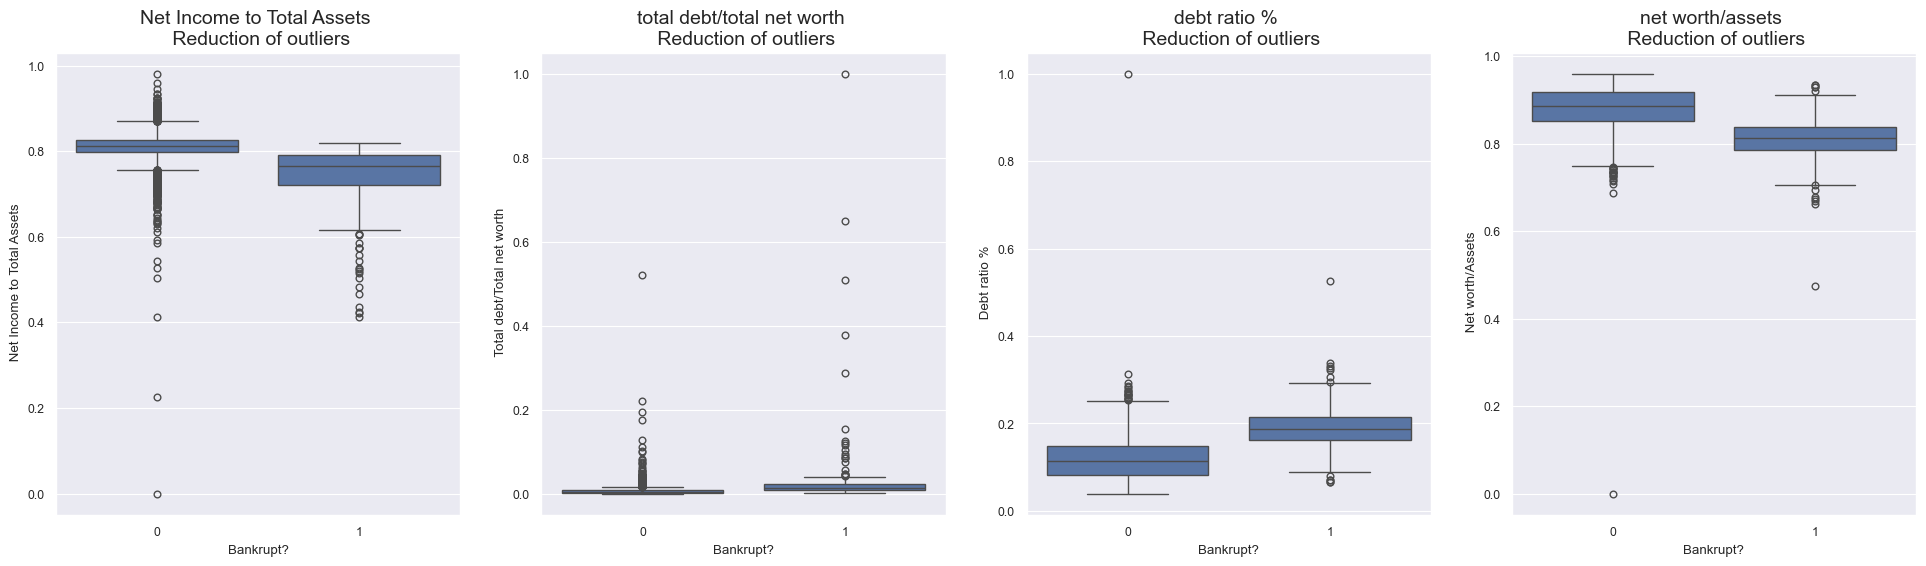

In [54]:
f, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize = (24, 6))

# Boxplots with outliers removed

sns.boxplot(x="Bankrupt?", y=" Net Income to Total Assets", data=new_df, ax=ax1)
ax1.set_title("Net Income to Total Assets \n Reduction of outliers", fontsize=14)

sns.boxplot(x="Bankrupt?", y=" Total debt/Total net worth", data=new_df, ax=ax2)
ax2.set_title("total debt/total net worth \n Reduction of outliers", fontsize=14)

sns.boxplot(x="Bankrupt?", y=" Debt ratio %", data=new_df, ax=ax3)
ax3.set_title("debt ratio % \n Reduction of outliers", fontsize=14)

sns.boxplot(x="Bankrupt?", y=" Net worth/Assets", data=new_df, ax=ax4)
ax4.set_title("net worth/assets \n Reduction of outliers", fontsize=14)

plt.show()

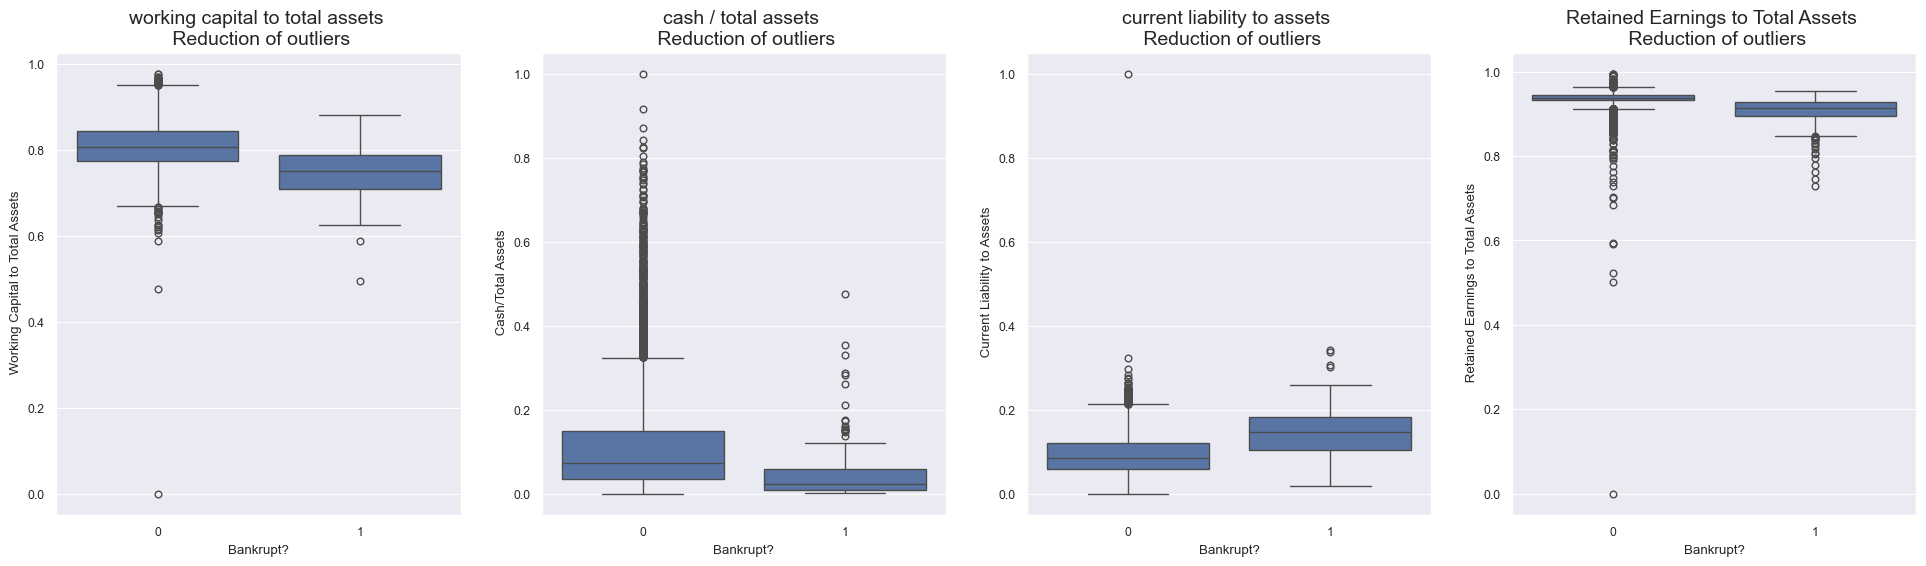

In [56]:
f,(ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(24, 6))

# Boxplots with outliers removed

sns.boxplot(x="Bankrupt?", y=' Working Capital to Total Assets', data=new_df, ax=ax1)
ax1.set_title("working capital to total assets \n Reduction of outliers", fontsize=14)

sns.boxplot(x="Bankrupt?", y=' Cash/Total Assets', data=new_df, ax=ax2)
ax2.set_title("cash / total assets \n Reduction of outliers", fontsize=14)

sns.boxplot(x="Bankrupt?", y=' Current Liability to Assets', data=new_df, ax=ax3)
ax3.set_title("current liability to assets \n Reduction of outliers", fontsize=14)

sns.boxplot(x="Bankrupt?", y=' Retained Earnings to Total Assets', data=new_df, ax=ax4)
ax4.set_title("Retained Earnings to Total Assets \n Reduction of outliers", fontsize=14)

plt.show()

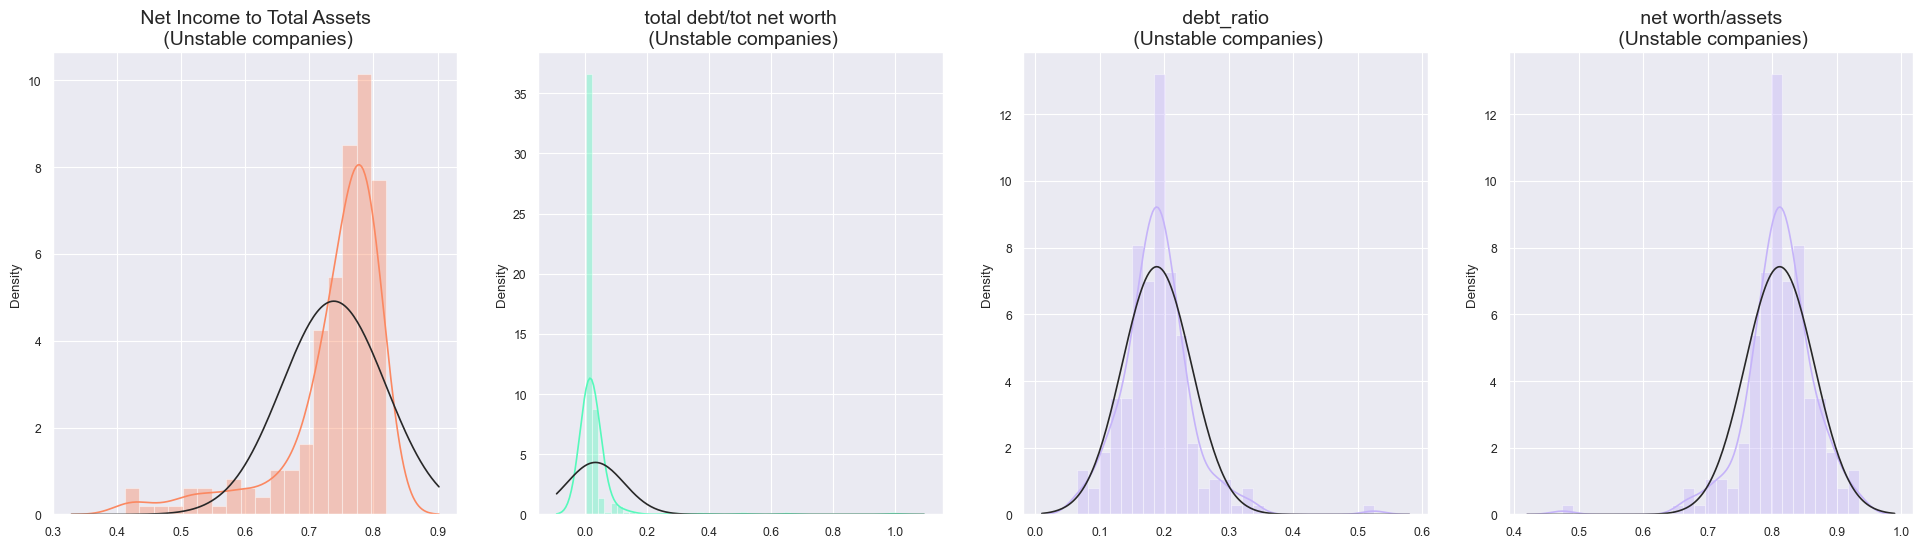

In [58]:
# Plotting the feature distribution for close to bankruptcy companies

f, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize = (24, 6))

cash_flow_rate = new_df[' Net Income to Total Assets'].loc[new_df['Bankrupt?'] == 1].values
sns.distplot(cash_flow_rate, ax=ax1, fit=norm, color='#FB8861')
ax1.set_title(' Net Income to Total Assets \n (Unstable companies)', fontsize=14)

tot_debt_net = new_df[' Total debt/Total net worth'].loc[new_df['Bankrupt?'] == 1].values
sns.distplot(tot_debt_net, ax=ax2, fit=norm, color='#56F9BB')
ax2.set_title(' total debt/tot net worth \n (Unstable companies)', fontsize=14)

debt_ratio = new_df[' Debt ratio %'].loc[new_df['Bankrupt?'] == 1].values
sns.distplot(debt_ratio, ax=ax3, fit=norm, color='#C5B3F9')
ax3.set_title(' debt_ratio \n (Unstable companies)', fontsize=14)

net_worth_assets = new_df[' Net worth/Assets'].loc[new_df['Bankrupt?'] == 1].values
sns.distplot(net_worth_assets, ax=ax4, fit=norm, color='#C5B3F9')
ax4.set_title(' net worth/assets \n (Unstable companies)', fontsize=14)

plt.show()

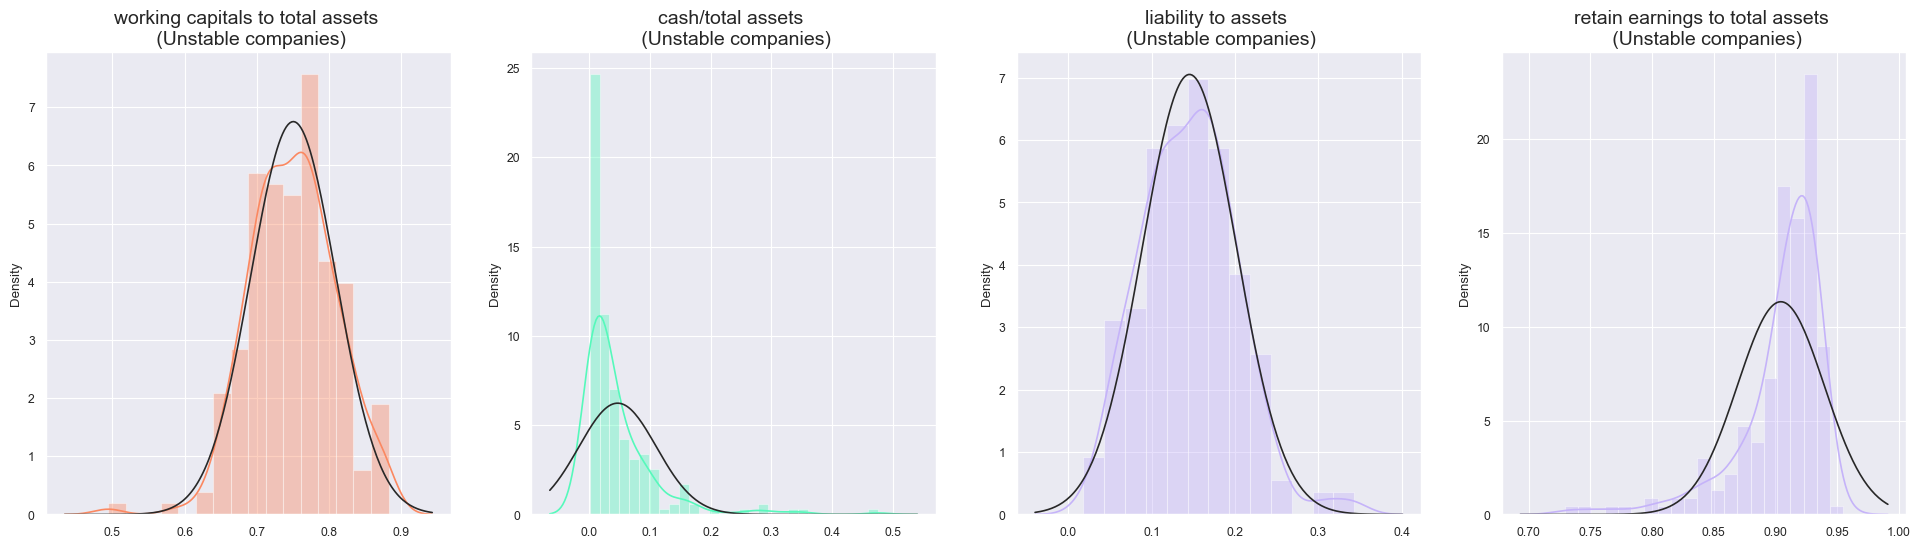

In [60]:
f, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(24, 6))

working_cap = new_df[' Working Capital to Total Assets'].loc[new_df['Bankrupt?'] == 1].values
sns.distplot(working_cap, ax=ax1, fit=norm, color='#FB8861')
ax1.set_title('working capitals to total assets \n (Unstable companies)', fontsize=14)

cash_tot_assets = new_df[' Cash/Total Assets'].loc[new_df['Bankrupt?'] == 1].values
sns.distplot(cash_tot_assets, ax=ax2, fit=norm, color='#56F9BB')
ax2.set_title('cash/total assets \n (Unstable companies)', fontsize=14)

asset_liab = new_df[' Current Liability to Assets'].loc[new_df['Bankrupt?'] == 1].values
sns.distplot(asset_liab, ax=ax3, fit=norm, color='#C5B3F9')
ax3.set_title('liability to assets \n (Unstable companies)', fontsize=14)

operating_funds = new_df[' Retained Earnings to Total Assets'].loc[new_df['Bankrupt?'] == 1].values
sns.distplot(operating_funds, ax=ax4, fit=norm, color='#C5B3F9')
ax4.set_title('retain earnings to total assets \n (Unstable companies)', fontsize=14)

plt.show()

We can see that removing the extreme outliers definitely helps to obtain more "bell shape" distributions

In [63]:
# Dividing Data and Labels

labels = new_df['Bankrupt?']
new_df = new_df.drop(['Bankrupt?'], axis = 1)

In [65]:
def log_trans(data): 

    for col in data: 
        skew = data[col].skew()
        if skew > 0.5 or skew < -0.5:
            data[col] = np.log1p(data[col])
        else: 
            continue

    return data

data_norm = log_trans(new_df)

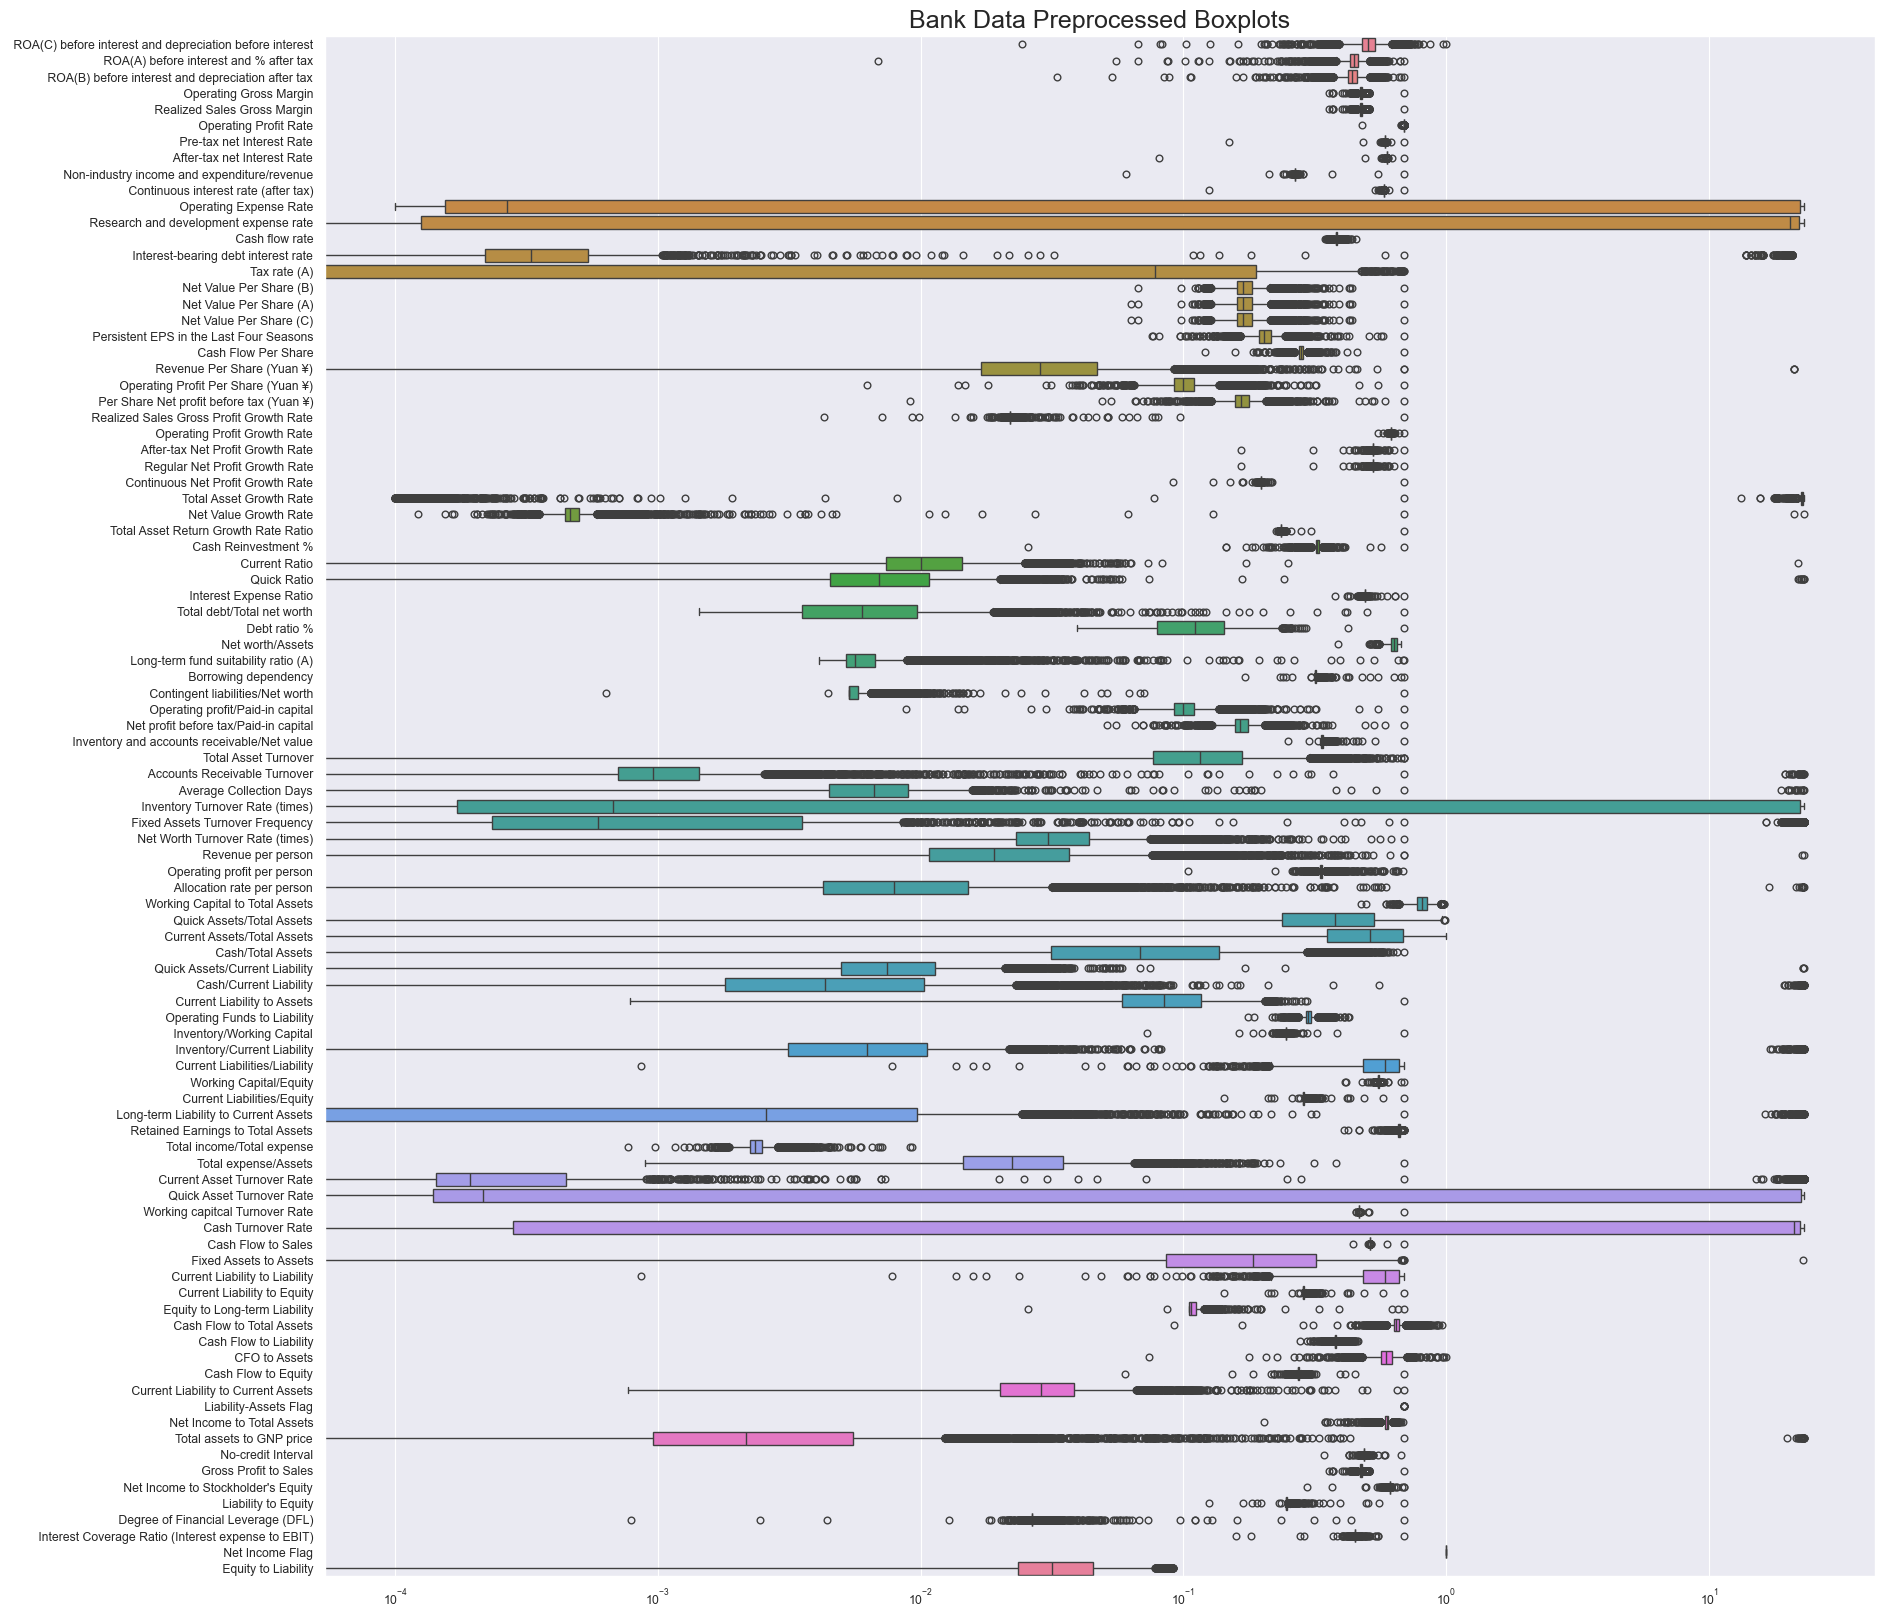

In [67]:
# Plotting Boxplots of the preprocessed numerical features

plt.figure(figsize = (20, 20))
ax = sns.boxplot(data = data_norm, orient="h")
ax.set_title('Bank Data Preprocessed Boxplots', fontsize = 18)
ax.set(xscale="log")
plt.show()

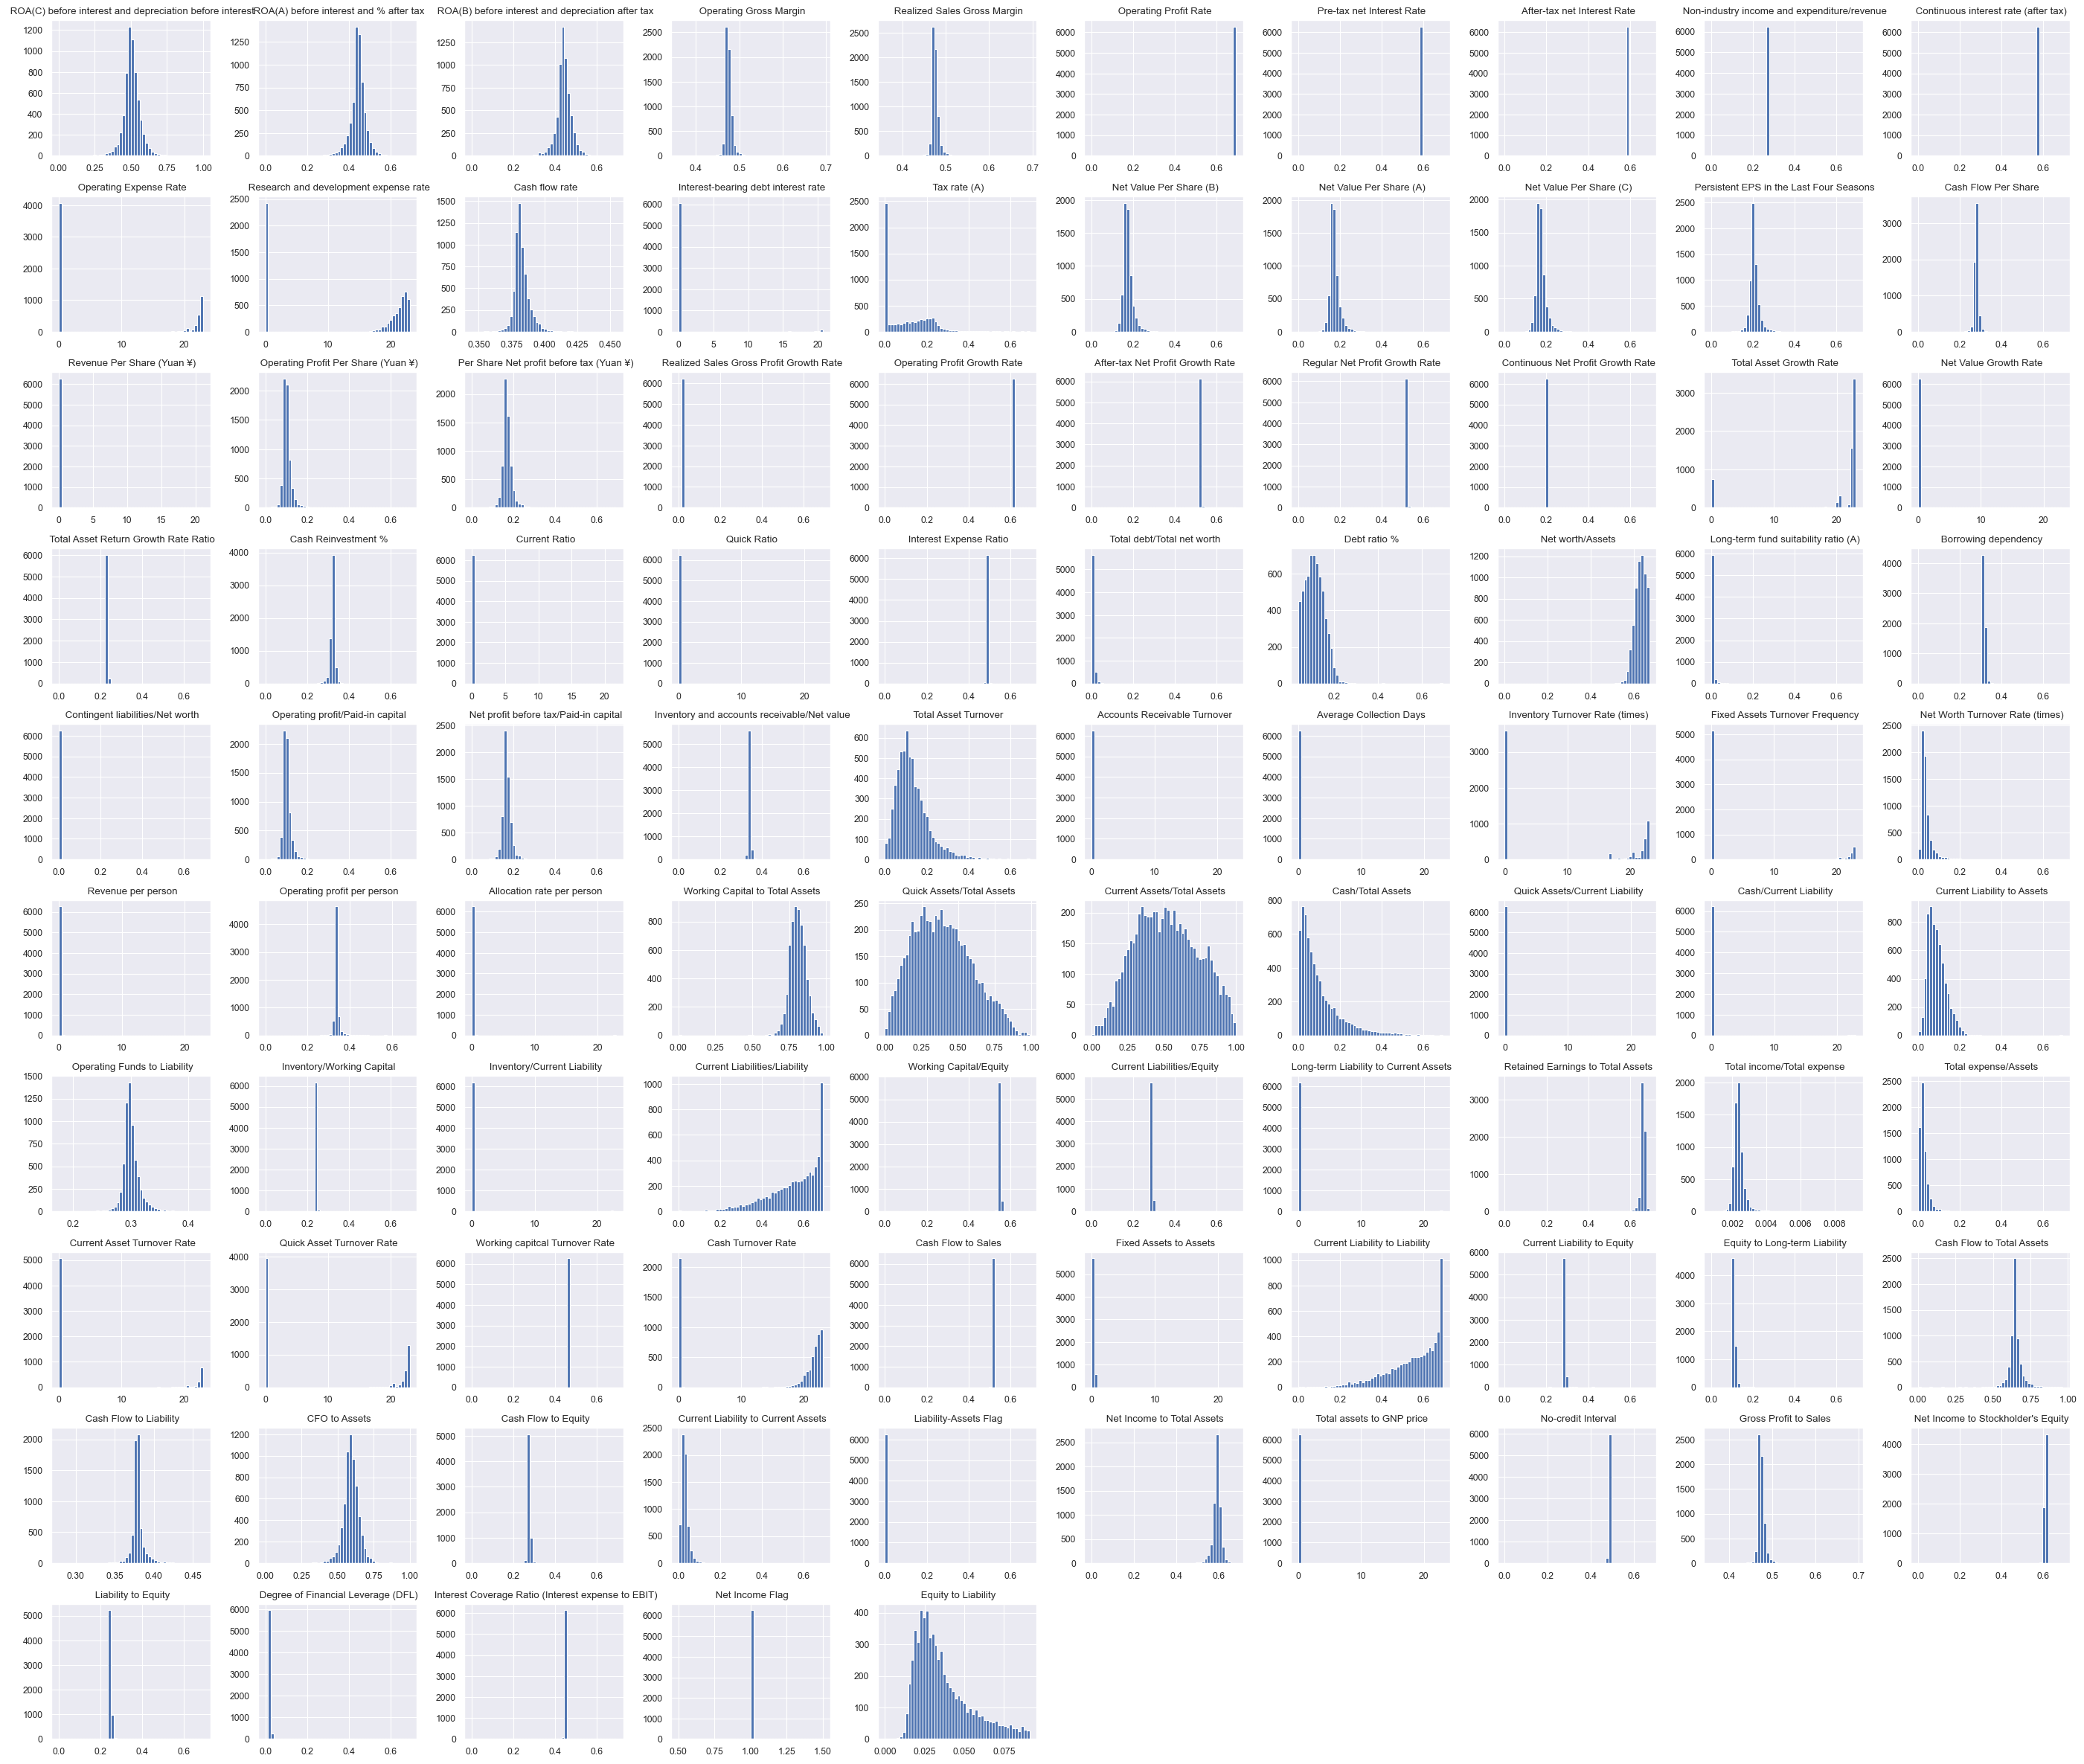

In [69]:
data_norm.hist(figsize = (35,30), bins = 50)
plt.show()

In [82]:
# Splitting the Train and Test Data

X_raw,X_test,y_raw,y_test = train_test_split(
    data_norm,
    labels,
    test_size=0.2,          # 20% test, 80% train
    stratify=labels,        # keep class ratios the same
    random_state=42
)

## SMOTE

Let's see if using SMOTE as oversamping technique can help us improve the performance. Although it is likely that SMOTE will be more accurate than random under-sampling, it will take more time to train since no rows are eliminated as previously stated

## MODELING

Now, let's see what we can do with our models. We will see the performances on the cleaned undersampled data and on the SMOTE oversampled data. For this part, we decided to use a few different models: 
- Logistic Regression
- SVC
- Random Forest Classifier
- CatBoost Classifier

In [97]:
# Stratified Cross Validation Splitting

sss = StratifiedKFold(n_splits=5, random_state=None, shuffle=False)

for train_index, test_index in sss.split(X_raw,y_raw):
    
    print("Train:", train_index, "Test:", test_index)
    X_train_sm, X_val_sm = X_raw.iloc[train_index], X_raw.iloc[test_index]
    y_train_sm, y_val_sm = y_raw.iloc[train_index], y_raw.iloc[test_index]

# Check the Distribution of the labels


# Turn into an array
X_train_sm = X_train_sm.values
X_val_sm = X_val_sm.values
y_train_sm = y_train_sm.values
y_val_sm = y_val_sm.values

# See if both the train and test label distribution are similarly distributed
train_unique_label, train_counts_label = np.unique(y_train_sm, return_counts=True)
test_unique_label, test_counts_label = np.unique(y_val_sm, return_counts=True)
print('-' * 84)

print('Label Distributions: \n')
print(train_counts_label/ len(y_train_sm))
print(test_counts_label/ len(y_val_sm))

Train: [ 998  999 1000 ... 5013 5014 5015] Test: [   0    1    2 ... 1093 1144 1150]
Train: [   0    1    2 ... 5013 5014 5015] Test: [ 998  999 1000 ... 2004 2006 2044]
Train: [   0    1    2 ... 5013 5014 5015] Test: [2005 2007 2008 ... 3011 3012 3013]
Train: [   0    1    2 ... 5013 5014 5015] Test: [2971 2983 2984 ... 4014 4015 4016]
Train: [   0    1    2 ... 4014 4015 4016] Test: [3915 3975 3981 ... 5013 5014 5015]
------------------------------------------------------------------------------------
Label Distributions: 

[0.96536257 0.03463743]
[0.96510469 0.03489531]


In [93]:
# Coerce to pandas for .iloc (safe even if already pandas)
#X = pd.DataFrame(X_raw) if not hasattr(X_raw, "iloc") else X_raw
#y = pd.Series(y_raw)    if not hasattr(y_raw, "iloc") else y_raw

#sss = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

#for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y), 1):
#    X_train_sm, X_val_sm = X.iloc[tr_idx], X.iloc[va_idx]
#    y_train_sm, y_val_sm = y.iloc[tr_idx], y.iloc[va_idx]

#    print(f"\nFold {fold}")
#    print("Train dist:", y_train_sm.value_counts(normalize=True).sort_index().to_dict())
#    print("Val   dist:", y_val_sm.value_counts(normalize=True).sort_index().to_dict())

    # If your downstream code needs NumPy:
#    X_train_arr, X_val_arr = X_train_sm.values, X_val_sm.values
#    y_train_arr, y_val_arr = y_train_sm.values, y_val_sm.values


Fold 1
Train dist: {0: 0.9653539381854437, 1: 0.03464606181455633}
Val   dist: {0: 0.9651394422310757, 1: 0.0348605577689243}

Fold 2
Train dist: {0: 0.9651133815100922, 1: 0.0348866184899078}
Val   dist: {0: 0.9661016949152542, 1: 0.03389830508474576}

Fold 3
Train dist: {0: 0.965362571642163, 1: 0.03463742835783703}
Val   dist: {0: 0.9651046859421735, 1: 0.03489531405782652}

Fold 4
Train dist: {0: 0.965362571642163, 1: 0.03463742835783703}
Val   dist: {0: 0.9651046859421735, 1: 0.03489531405782652}

Fold 5
Train dist: {0: 0.965362571642163, 1: 0.03463742835783703}
Val   dist: {0: 0.9651046859421735, 1: 0.03489531405782652}


## Logistic Regression 

In [99]:
# List to append the score and then find the average

accuracy_lst_reg = []
precision_lst_reg = []
recall_lst_reg = []
f1_lst_reg = []
auc_lst_reg = []

log_reg_sm = LogisticRegression()
log_reg_params = {"penalty": ['l2'],
                  'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
                  'class_weight': ['balanced',None],
                  'solver':['newton-cg', 'lbfgs', 'liblinear', 'sag', 'saga']}

rand_log_reg = RandomizedSearchCV(LogisticRegression(), log_reg_params, n_iter=4)


for train, val in sss.split(X_train_sm, y_train_sm):
    pipeline_reg = imbalanced_make_pipeline(SMOTE(sampling_strategy='minority'), rand_log_reg) # SMOTE happens during Cross Validation not before..
    model_reg = pipeline_reg.fit(X_train_sm[train], y_train_sm[train])
    best_est_reg = rand_log_reg.best_estimator_
    prediction_reg = best_est_reg.predict(X_train_sm[val])
    
    accuracy_lst_reg.append(pipeline_reg.score(X_train_sm[val], y_train_sm[val]))
    precision_lst_reg.append(precision_score(y_train_sm[val], prediction_reg))
    recall_lst_reg.append(recall_score(y_train_sm[val], prediction_reg))
    f1_lst_reg.append(f1_score(y_train_sm[val], prediction_reg))
    auc_lst_reg.append(roc_auc_score(y_train_sm[val], prediction_reg))

print('---' * 45)
print('')
print('Logistic Regression (SMOTE) results:')
print('')
print("accuracy: {}".format(np.mean(accuracy_lst_reg)))
print("precision: {}".format(np.mean(precision_lst_reg)))
print("recall: {}".format(np.mean(recall_lst_reg)))
print("f1: {}".format(np.mean(f1_lst_reg)))
print('')
print('---' * 45)

---------------------------------------------------------------------------------------------------------------------------------------

Logistic Regression (SMOTE) results:

accuracy: 0.8706623851330578
precision: 0.18786784555914982
recall: 0.7997354497354496
f1: 0.30268798167562877

---------------------------------------------------------------------------------------------------------------------------------------


## Interpretation

- High recall(~0.80): we're catching most positives
- Very low precision(~0.2): ~81% of predicted positives are false alarms
- Accuracy looks "fine" only because the data are imbalanced; it's not a good guide here
- Why so low precision? We're using the default 0.5 threshold on a model trained with SMOTE / class_weight, which often shifts scores upward and creats lots of false positives at 0.5

Also note two technical issues in this loop: 
- We compute predictions with best_est_reg, which pulls the estimator out of the RandomizedSearchCV object we reused across folds. That leaks state between folds and bypasses the pipeline. Use the fitted pipeline_reg to predict on the fold's validation split.
- We append roc_auc_score(..., prediction_reg) using hard labels; AUC needs probabilities

In [103]:
# Printing the classification report

label = ['Fin.Stable', 'Fin.Unstable']
pred_reg_sm = best_est_reg.predict(X_val_sm)
print(classification_report(y_val_sm, pred_reg_sm, target_names=label))

              precision    recall  f1-score   support

  Fin.Stable       0.99      0.89      0.94       968
Fin.Unstable       0.20      0.71      0.31        35

    accuracy                           0.89      1003
   macro avg       0.59      0.80      0.62      1003
weighted avg       0.96      0.89      0.92      1003



## Interpretation

Interpretation in counts (approx):
- Positives in set = 35
- Recall 0.71 -> TP = 25, FN = 10
- Precision 0.20 -> predicted positives -> FP = 100
- Majority class looks great (precision 0.99), which drives overall accuracy 0.89
- Takeaway: the model flags many accounts; most flags are wrong. If false positives are costly, you need a higher decision threshold or a model with better ranking

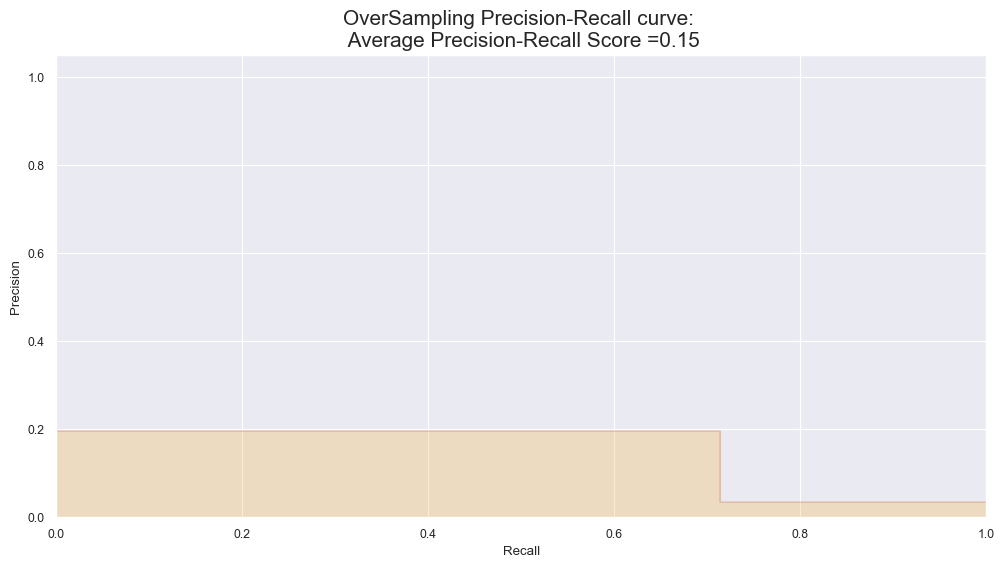

In [105]:
# Plotting Precision-Recall curve

y_score_reg = best_est_reg.predict(X_val_sm)

average_precision = average_precision_score(y_val_sm, y_score_reg)

fig = plt.figure(figsize=(12, 6))

precision, recall, _ = precision_recall_curve(y_val_sm, y_score_reg)

plt.step(recall, precision, color='r', alpha=0.2, where='post')
plt.fill_between(recall, precision, step = 'post', alpha=0.2, color='#F59B00')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.ylim([0.0, 1.05])
plt.xlim([0.0, 1.0])
plt.title('OverSampling Precision-Recall curve: \n Average Precision-Recall Score ={0:0.2f}'.format(
    average_precision), fontsize=15)

plt.show()

## Cleaned Logistic Regression

/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_ite

              precision    recall  f1-score   support

  Fin.Stable       0.99      0.87      0.93       968
Fin.Unstable       0.17      0.74      0.28        35

    accuracy                           0.87      1003
   macro avg       0.58      0.81      0.60      1003
weighted avg       0.96      0.87      0.90      1003

ROC AUC: 0.8732880755608029
Avg Precision (PR AUC): 0.44895518592508576


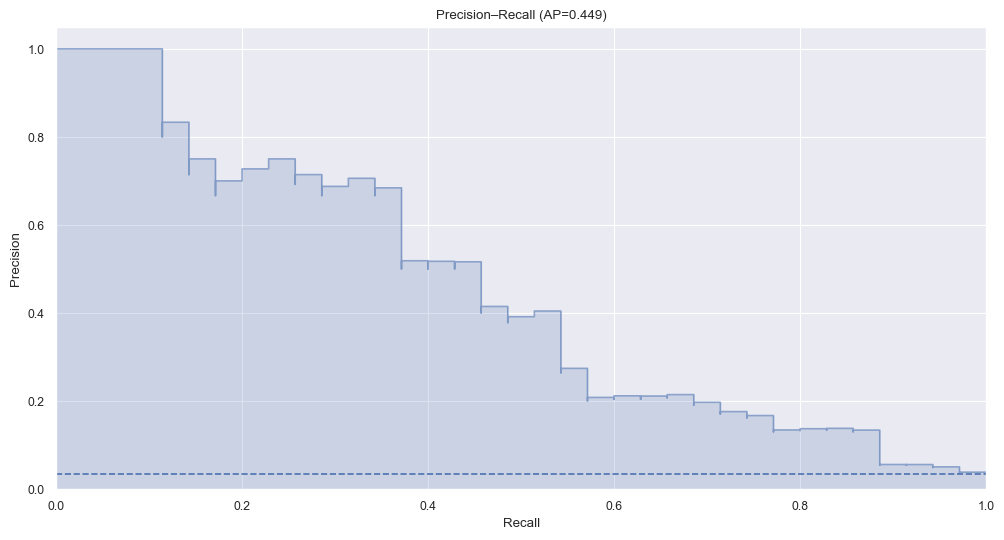

Best F1 threshold: 0.9535690922422082


In [124]:
#from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
#from sklearn.linear_model import LogisticRegression
#from sklearn.metrics import (classification_report, precision_recall_curve,
#                             average_precision_score, roc_auc_score)
#from imblearn.pipeline import make_pipeline as imbalanced_make_pipeline
#from imblearn.over_sampling import SMOTE
from scipy.stats import loguniform
#import numpy as np
#import matplotlib.pyplot as plt

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_dist = {
    "logisticregression__penalty": ["l2"],
    "logisticregression__C": loguniform(1e-3, 1e3),
    "logisticregression__class_weight": ["balanced", None],
    "logisticregression__solver": ["lbfgs", "saga"],  # stable with l2
    "logisticregression__max_iter": [2000],
}

pipe = imbalanced_make_pipeline(SMOTE(sampling_strategy="minority"),
                                LogisticRegression())

search = RandomizedSearchCV(
    pipe,
    param_distributions=param_dist,
    n_iter=30,
    scoring="average_precision",   # better for imbalance
    cv=skf,
    n_jobs=-1,
    random_state=42,
    refit=True
)

search.fit(X_train_sm, y_train_sm)          # SMOTE only inside CV folds

final_model = search.best_estimator_        # this is the full pipeline
y_pred = final_model.predict(X_val_sm)      # uses 0.5 threshold
y_scores = final_model.predict_proba(X_val_sm)[:, 1]

print(classification_report(y_val_sm, y_pred, target_names=["Fin.Stable","Fin.Unstable"]))
print("ROC AUC:", roc_auc_score(y_val_sm, y_scores))
print("Avg Precision (PR AUC):", average_precision_score(y_val_sm, y_scores))

# PR curve
prec, rec, thr = precision_recall_curve(y_val_sm, y_scores)
ap = average_precision_score(y_val_sm, y_scores)
plt.figure(figsize=(12,6))
plt.step(rec, prec, where="post", alpha=0.6)
plt.fill_between(rec, prec, step="post", alpha=0.2)
plt.hlines(y=y_val_sm.mean(), xmin=0, xmax=1, linestyles="--")  # baseline
plt.xlim(0,1); plt.ylim(0,1.05)
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title(f"Precision–Recall (AP={ap:.3f})")
plt.show()

# Pick a threshold to trade precision/recall (optional)
f1 = 2 * (prec*rec) / (prec+rec + 1e-12)
best_idx = np.nanargmax(f1)
best_thr = thr[best_idx]
print("Best F1 threshold:", best_thr)


## Interpretation

#### What the numbers say
- Imbalance / baseline: Positives = 35 of 1003 -> base rate = 3.5%. A random ranker would have AP = 0.035 (our dashed line)
- ROC AUC = 0.873 -> the model ranks positives above negatives quite well. ROC can look high even with many false positives in imbalanced data
- PR AUC (AP) = 0.449 -> On the positive class, the model is ~12-13x better than random (0.449 vs 0.035). The curve shows good precision at low recall (left side), which falls as recall increases - typical trade-off
- Classification report (at threshold 0.5):
    - Fin.Unstable (positive): precision 0.17, recall 0.74, F1 0.28.
      - Approx counts: TP ≈ 26, FN ≈ 9, FP ≈ 121, TN ≈ 847.
      - Interpretation: you catch most positives, but ~83% of your alerts are false alarms.
    - Overall accuracy 0.87 is dominated by the majority class and is not a good quality signal here.

- Best F1 threshold ≈ 0.954 → To balance precision and recall for this dataset, you must use a much higher threshold than 0.5. That will cut many false positives (precision ↑) while lowering recall—closer to the left/top of your PR curve where precision is high.

## Random Forest Classifier

In [116]:
# List to append the score and then find the average

accuracy_lst_rfc = []
precision_lst_rfc = []
recall_lst_rfc = []
f1_lst_rfc = []
auc_lst_rfc = []

rfc_sm = RandomForestClassifier()
rfc_params = {'max_features' : ['auto', 'sqrt', 'log2'],
              'random_state' : [42],
              'class_weight' : ['balanced','balanced_subsample'],
              'criterion' : ['gini', 'entropy'],
              'bootstrap' : [True,False]}
    
    
rand_rfc = RandomizedSearchCV(rfc_sm, rfc_params, n_iter=4)


for train, val in sss.split(X_train_sm, y_train_sm):
    pipeline_rfc = imbalanced_make_pipeline(SMOTE(sampling_strategy='minority'), rand_rfc) # SMOTE happens during Cross Validation not before..
    model_rfc = pipeline_rfc.fit(X_train_sm, y_train_sm)
    best_est_rfc = rand_rfc.best_estimator_
    prediction_rfc = best_est_rfc.predict(X_train_sm[val])
    
    accuracy_lst_rfc.append(pipeline_rfc.score(X_train_sm[val], y_train_sm[val]))
    precision_lst_rfc.append(precision_score(y_train_sm[val], prediction_rfc))
    recall_lst_rfc.append(recall_score(y_train_sm[val], prediction_rfc))
    f1_lst_rfc.append(f1_score(y_train_sm[val], prediction_rfc))
    auc_lst_rfc.append(roc_auc_score(y_train_sm[val], prediction_rfc))
    
print('---' * 45)
print('')
print("accuracy: {}".format(np.mean(accuracy_lst_rfc)))
print("precision: {}".format(np.mean(precision_lst_rfc)))
print("recall: {}".format(np.mean(recall_lst_rfc)))
print("f1: {}".format(np.mean(f1_lst_rfc)))
print('---' * 45)

---------------------------------------------------------------------------------------------------------------------------------------

accuracy: 1.0
precision: 1.0
recall: 1.0
f1: 1.0
---------------------------------------------------------------------------------------------------------------------------------------


## Interpretation

These results are not real - they're from data leakage:
- Inside the loop we do pipeline_rfc.fit(X_train_sm, y_train_sm) (fits the entire set), then evaluate on the fold's validation rows. That's in-sample evaluation, so a RF can look perfect.
- We also predict with best_est_rfc (the inner RandomizedSearchCV object reused across folds), which further mixes state between folds
- We compute AUC with hard labels (roc_auc_score(..., prediction_rfc)), which isn't a ROC AUC

Overall: ignore these "1.0" metrics; they don't say anything about generalization

In [132]:
target_names = ['Fin.Stable', 'Fin.Unstable']  # length must equal number of classes
print(classification_report(y_val_sm, smote_prediction_rfc,
                            labels=[0,1], target_names=target_names, digits=3))

              precision    recall  f1-score   support

  Fin.Stable      0.980     0.982     0.981       968
Fin.Unstable      0.485     0.457     0.471        35

    accuracy                          0.964      1003
   macro avg      0.733     0.720     0.726      1003
weighted avg      0.963     0.964     0.964      1003



## Interpretation

Translate to counts (approx): 
- Positives in set = 35
- Recall 0.457 -> TP = 16, FN = 19
- Precision 0.485 -> predicted positives = 33 -> FP = 17
- Negatives = 968 -> TN = 951

So, at the default 0.5 threshold our RF: 
- Finds ~46% of the actual positives,
- With ~49% precision (about half of its alerts are correct),
- While keeping FPR low (~1.9%) and overall accuracy high (driven by the majority class).

Compared to our earlier logistic (prec = 0.17, rec = 0.74), RF has much higher precision but lower recall - it's a different point on the precision/recall trade-off. Which is "better" depends on your cost of false positives vs. false negatives. 

Also note the base rate: 35/1003 = 3.5%. Getting 48.5% precision is ~14x higher than random - useful context

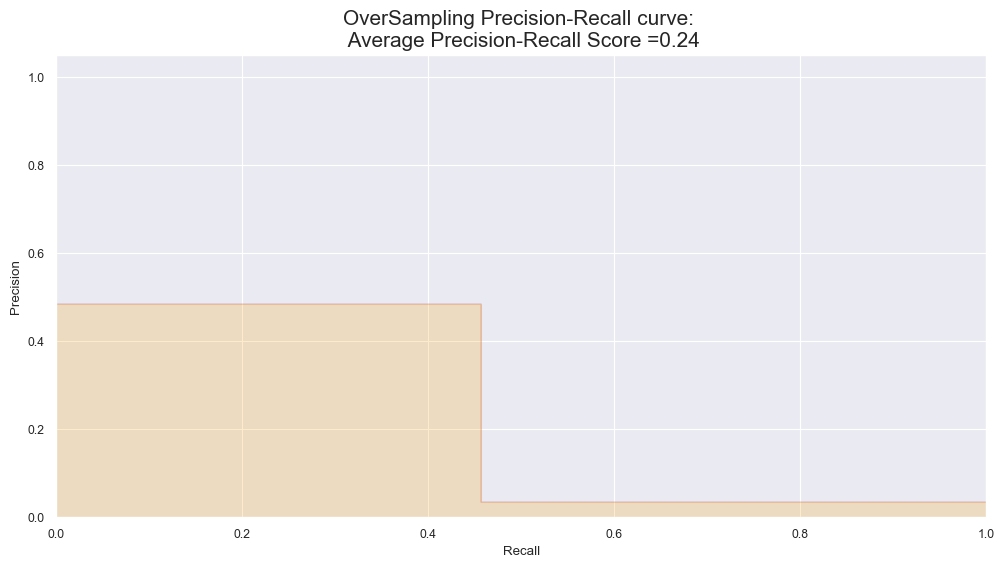

In [138]:
# Plotting Precision-Recall curve

y_score_rfc = best_est_rfc.predict(X_val_sm)

average_precision_rfc = average_precision_score(y_val_sm, y_score_rfc)

fig = plt.figure(figsize=(12,6))

precision_rfc, recall_rfc, _ = precision_recall_curve(y_val_sm, y_score_rfc)

plt.step(recall_rfc, precision_rfc, color='r', alpha=0.2,
         where='post')
plt.fill_between(recall_rfc, precision_rfc, step='post', alpha=0.2,
                 color='#F59B00')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.ylim([0.0, 1.05])
plt.xlim([0.0, 1.0])
plt.title('OverSampling Precision-Recall curve: \n Average Precision-Recall Score ={0:0.2f}'.format(
          average_precision_rfc), fontsize=15)

plt.show()

## Interpretation

We computed it with hard labels: 

With 0/1 inputs, the PR curve degenerates to a rectangle: precision = 0.485 up to recall = 0.457, then it drops to the prevelance (~0.035) at recall=1.0. The area of that rectangle = 0.485*0.457 + 0.035&(1-0.457) = 0.24, which is exactly what we see. 

Overall: AP=0.24 here is not the model's ranking ability; it's just the area implied by the single 0.5 decision threshold versus "everyone positive". 

We cannot compare this AP=0.24 to the logistic model's AP=0.449 we computed earlier with probabilities - those are apples and oranges. 

#### What these results really tell us
- The RF at threshold 0.5 is operating at (precision=0.49, recall=0.46). That's decent precision given a 3.5% base rate, with moderate recall.
- The model very likely has a useful ranking (ROC/PR) but we haven't measured it yet because we passed labels, not scores.
- The "perfect" CV metrics are artifacts of leakage and should be discarded

## Cleaned RandomForest Classifier

In [141]:
#from imblearn.pipeline import make_pipeline as imbalanced_make_pipeline
#from imblearn.over_sampling import SMOTE
#from sklearn.ensemble import RandomForestClassifier
#from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
#from sklearn.metrics import classification_report, roc_auc_score, average_precision_score

sss = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

pipe = imbalanced_make_pipeline(
    SMOTE(sampling_strategy='minority'),
    RandomForestClassifier(random_state=42, n_jobs=-1)
)

param_dist = {
    'randomforestclassifier__n_estimators': [200,400,800],
    'randomforestclassifier__max_depth': [None, 8, 16, 24],
    'randomforestclassifier__max_features': ['sqrt','log2', None],  # avoid 'auto'
    'randomforestclassifier__min_samples_split': [2,5,10],
    'randomforestclassifier__min_samples_leaf': [1,2,4],
    'randomforestclassifier__class_weight': ['balanced','balanced_subsample'],
    'randomforestclassifier__criterion': ['gini','entropy'],
    'randomforestclassifier__bootstrap': [True, False],
}

search = RandomizedSearchCV(
    pipe, param_distributions=param_dist, n_iter=40,
    scoring='average_precision', cv=sss, n_jobs=-1,
    random_state=42, refit=True
)

search.fit(X_train_sm, y_train_sm)          # CV happens inside; SMOTE only on train folds
final_model = search.best_estimator_

y_pred   = final_model.predict(X_val_sm)
y_scores = final_model.predict_proba(X_val_sm)[:,1]

print(classification_report(y_val_sm, y_pred,
                            labels=[0,1],
                            target_names=['Fin.Stable','Fin.Unstable'],
                            digits=3))
print("ROC AUC:", roc_auc_score(y_val_sm, y_scores))
print("PR AUC:",  average_precision_score(y_val_sm, y_scores))


              precision    recall  f1-score   support

  Fin.Stable      0.982     0.977     0.980       968
Fin.Unstable      0.450     0.514     0.480        35

    accuracy                          0.961      1003
   macro avg      0.716     0.746     0.730      1003
weighted avg      0.964     0.961     0.962      1003

ROC AUC: 0.920439787485242
PR AUC: 0.5026024904980773


## Interpretation

This Random Forest is clearly stronger than the earlier logistic

#### What these numbers mean
- Imbalance/base rate: 35 / 1003 = 3.5% positives
- Ranking quality:
    - ROC AUC = 0.920 -> very good separation overall
    - PR AUC = 0.503 -> ~14x better than random (0.503 vs 0.035 baseline). This is the right metric for our class-imbalanced target
- At the default 0.5 threshold
    - Fin.Unstable precision = 0.450, recall = 0.514, F1 = 0.480
    - Back-of-envelope counts (support = 35): TP = 18, FN = 17, FP = 22, TN = 946 -> FPR = 2.3%
    - Overall accuracy 0.961 is high but mainly reflects the majority class

Bottom line: our RF ranks cases well and, at 0.5, finds ~half of the positives while half of alerts are true. Whether that's "good" depends on our tolerance for false positives vs. misses

## XGBoost

In [147]:
# List to append the score and then find the average

accuracy_lst_xgb = []
precision_lst_xgb = []
recall_lst_xgb = []
f1_lst_xgb = []
auc_lst_xgb = []

xgb_sm = xgb.XGBClassifier(random_state=42)
xgb_params = {'eta' : [0.1, 0.01, 0.001], # Learning Rate
              'eval_metric': ['logloss'],
              'max_depth': [3, 6, 9], 
              'lambda': [1, 1.5, 2], # L2 regularization (higher values make model more conservative)
              'alpha': [0, 0.5, 1]} # L1 regularization (higher values make model more conservative)

rand_xgb = RandomizedSearchCV(xgb_sm, xgb_params, n_iter=4)

for train, val in sss.split(X_train_sm, y_train_sm):
    pipeline_xgb = imbalanced_make_pipeline(SMOTE(sampling_strategy='minority'), rand_xgb) # SMOTE happens during Cross Validation not before
    model_xgb = pipeline_xgb.fit(X_train_sm, y_train_sm)
    best_est_xgb = rand_xgb.best_estimator_
    prediction_xgb = best_est_xgb.predict(X_train_sm[val])

    accuracy_lst_xgb.append(pipeline_xgb.score(X_train_sm[val], y_train_sm[val]))
    precision_lst_xgb.append(precision_score(y_train_sm[val], prediction_xgb))
    recall_lst_xgb.append(recall_score(y_train_sm[val], prediction_xgb))
    f1_lst_xgb.append(f1_score(y_train_sm[val], prediction_xgb))
    auc_lst_xgb.append(roc_auc_score(y_train_sm[val], prediction_xgb))

print('---' * 45)
print('')
print("accuracy: {}".format(np.mean(accuracy_lst_xgb)))
print("precision: {}".format(np.mean(precision_lst_xgb)))
print("recall: {}".format(np.mean(recall_lst_xgb)))
print("f1: {}".format(np.mean(f1_lst_xgb)))
print('---' * 45)

---------------------------------------------------------------------------------------------------------------------------------------

accuracy: 0.9935242839352428
precision: 0.9038461538461539
recall: 0.9928571428571429
f1: 0.9349999999999999
---------------------------------------------------------------------------------------------------------------------------------------


In [149]:
# Printing classification report

smote_prediction_xgb = best_est_xgb.predict(X_val_sm)
print(classification_report(y_val_sm, smote_prediction_xgb, target_names=label))

              precision    recall  f1-score   support

  Fin.Stable       0.98      0.97      0.98       968
Fin.Unstable       0.37      0.46      0.41        35

    accuracy                           0.95      1003
   macro avg       0.68      0.71      0.69      1003
weighted avg       0.96      0.95      0.96      1003



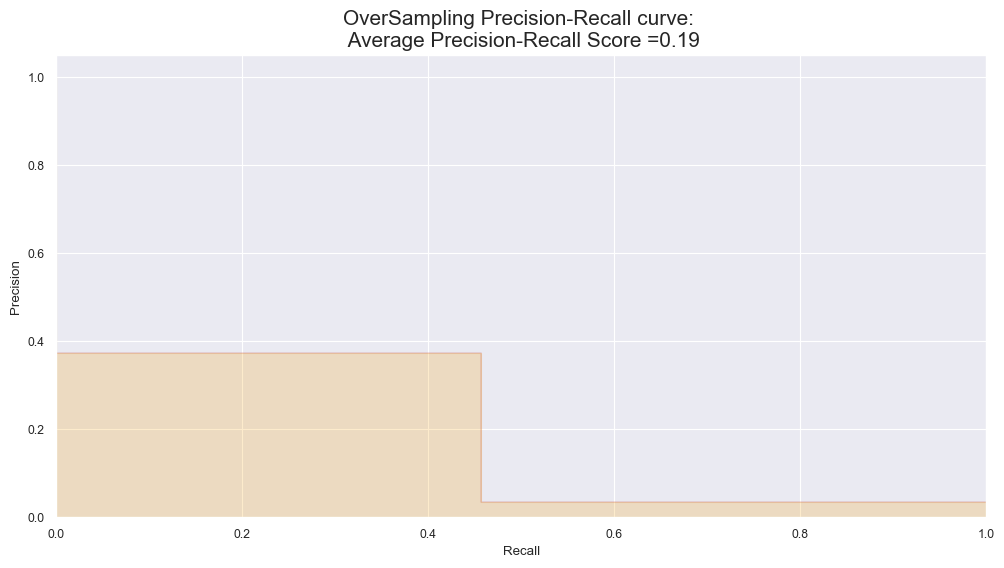

In [156]:
# Plotting Precision-Recall curve

y_score_xgb = best_est_xgb.predict(X_val_sm)

average_precision_xgb = average_precision_score(y_val_sm, y_score_xgb)

fig = plt.figure(figsize=(12,6))

precision_xgb, recall_xgb, _ = precision_recall_curve(y_val_sm, y_score_xgb)

plt.step(recall_xgb, precision_xgb, color='r', alpha=0.2,
         where='post')
plt.fill_between(recall_xgb, precision_xgb, step='post', alpha=0.2,
                 color='#F59B00')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.ylim([0.0, 1.05])
plt.xlim([0.0, 1.0])
plt.title('OverSampling Precision-Recall curve: \n Average Precision-Recall Score ={0:0.2f}'.format(
          average_precision_xgb), fontsize=15)

plt.show()

## Interpretation

#### What's trustworthy vs. misleading

The CV loop metrics (=0.99 acc, 0.90 prec, 0.99 recall, 0.935 F1) are not valid. 
- Inside the loop we fit on all X_train_sm and then "validate" on a slice of it, and we reuse the same RandomizedSearchCV object across folds. That's in-sample evaluation (leakage), so scores look unrealistically perfect. Also, AUC is computed from hard labels.

The hold-out classification report is the meaningful part: 
- Positives in set = 35
- Recall 0.46 -> TP = 16, FN = 19
- Precision 0.37 -> predicted positives = 43 -> FP = 27, so TN = 941
- False positive rate = 27/968 = 2.8%

Overall: at the default 0.5 threshold the XGBoost model catches ~46% of true positives, and ~37% of its alerts are correct (63% false alarms). Given a base rate of ~3.5% (35/1003), 37% precision is ~10x better than random, but it's weaker than our RandomForest (RF had ~0.45 precision and ~0.51 recall on the same split)

Our PR curve/AP = 0.19 is not the model's real PR AUC
- We plotted it with predict(...) (0/1 labels). That produces the rectangle we see and AP = 0.37*0.46 + 0.035*(1-0.46) = 0.19. To assess ranking quality, we must use probabilities

## Results

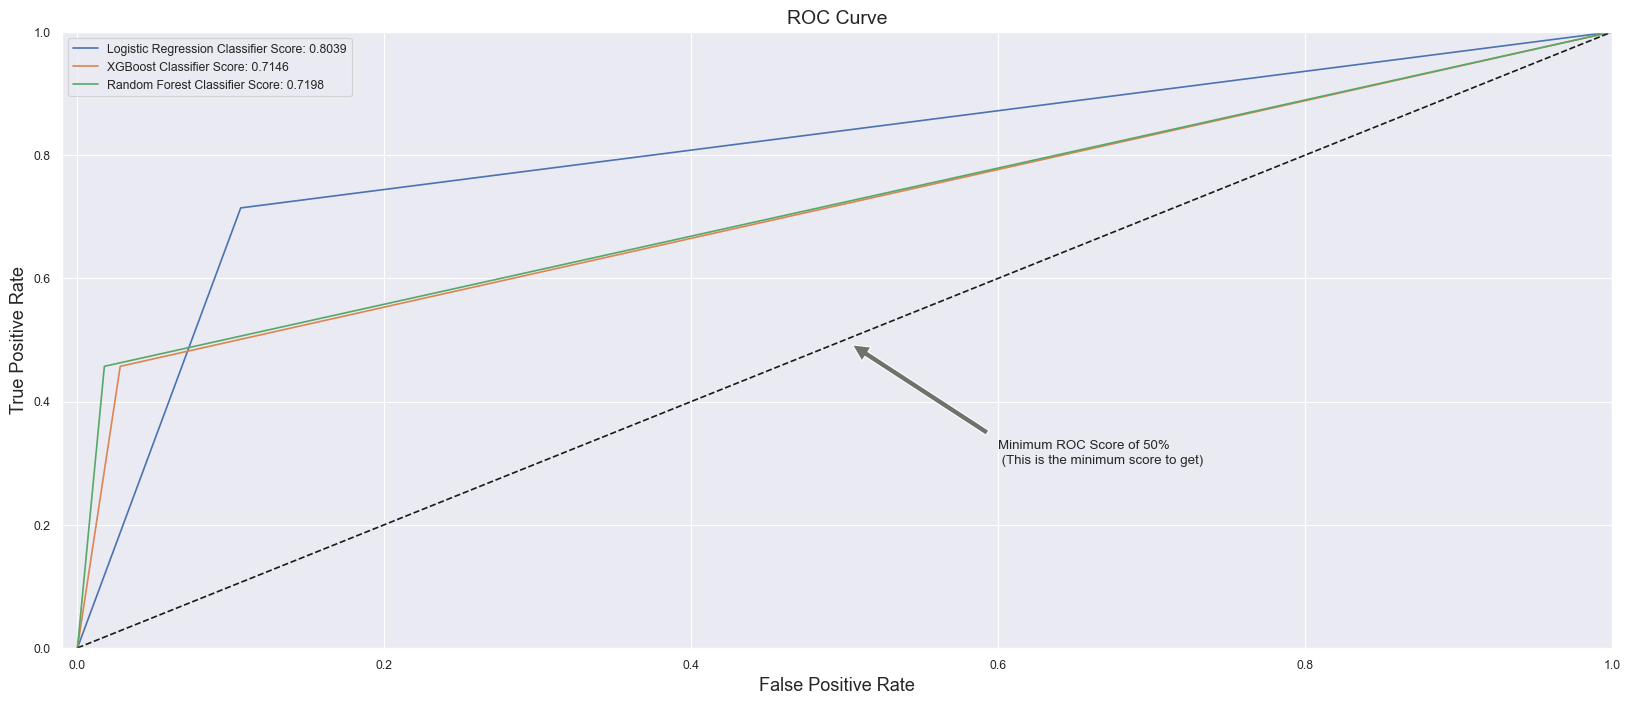

In [163]:
from sklearn.metrics import roc_curve

log_fpr, log_tpr, log_thresold = roc_curve(y_val_sm, pred_reg_sm)
rfc_fpr, rfc_tpr, rfc_threshold = roc_curve(y_val_sm, smote_prediction_rfc)
xgb_fpr, xgb_tpr, xgb_thresold = roc_curve(y_val_sm, smote_prediction_xgb)
#cat_fpr, cat_tpr, cat_thresold = roc_curve(y_val_sm, smote_prediction_cat)


def graph_roc_curve_multiple(log_fpr, log_tpr, rfc_fpr, rfc_tpr,xgb_fpr, xgb_tpr): #,cat_fpr, cat_tpr):
    plt.figure(figsize=(20,8))
    plt.title('ROC Curve', fontsize=14)
    plt.plot(log_fpr, log_tpr, label='Logistic Regression Classifier Score: {:.4f}'.format(roc_auc_score(y_val_sm, pred_reg_sm)))
    plt.plot(xgb_fpr, xgb_tpr, label='XGBoost Classifier Score: {:.4f}'.format(roc_auc_score(y_val_sm, smote_prediction_xgb)))
    #plt.plot(cat_fpr, cat_tpr, label='CatBoost Classifier Score: {:.4f}'.format(roc_auc_score(y_val_sm, smote_prediction_cat)))
    plt.plot(rfc_fpr, rfc_tpr, label='Random Forest Classifier Score: {:.4f}'.format(roc_auc_score(y_val_sm, smote_prediction_rfc)))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.axis([-0.01, 1, 0, 1])
    plt.xlabel('False Positive Rate', fontsize=13)
    plt.ylabel('True Positive Rate', fontsize=13)
    plt.annotate('Minimum ROC Score of 50% \n (This is the minimum score to get)', xy=(0.5, 0.5), xytext=(0.6, 0.3),
                arrowprops=dict(facecolor='#6E726D', shrink=0.05),
                )
    plt.legend()
    
graph_roc_curve_multiple(log_fpr, log_tpr, rfc_fpr, rfc_tpr,xgb_fpr, xgb_tpr) #,cat_fpr, cat_tpr)
plt.show()

## Interpretation

We're plotting a ROC curve with hard labels (0/1), not with scores / probabilities. That's why each curve has basically one kink and our AUCs (0.80 LR, 0.72 RF, 0.71 XGB) contradict the earlier results 

#### What this plot actually shows
- roc_curve(y, y_hat) where y_hat is 0/1 gives only three points:
    - (0,0) -> (FPR at 0.5, TPR at 0.5) -> (1,1)
    - The "AUC" we compute from that is just the area from this single operating point; it is not the model's ranking ability

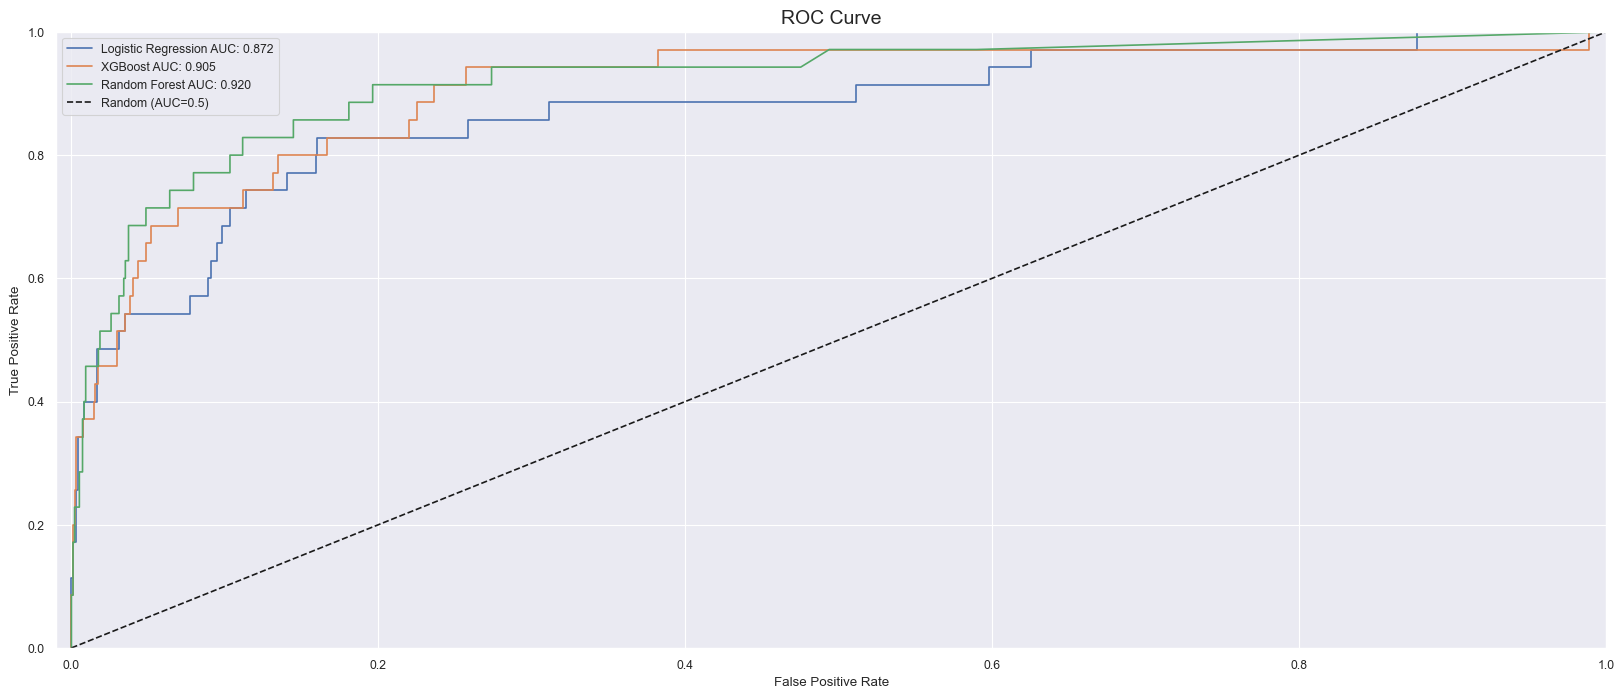

In [170]:
# use probabilities (or decision_function for linear SVMs)
log_scores = best_est_reg.predict_proba(X_val_sm)[:, 1]
rf_scores  = final_model.predict_proba(X_val_sm)[:, 1]
xgb_scores = best_est_xgb.predict_proba(X_val_sm)[:, 1]

from sklearn.metrics import roc_curve, roc_auc_score

log_fpr, log_tpr, _ = roc_curve(y_val_sm, log_scores)
rf_fpr,  rf_tpr,  _ = roc_curve(y_val_sm, rf_scores)
xgb_fpr, xgb_tpr, _ = roc_curve(y_val_sm, xgb_scores)

log_auc = roc_auc_score(y_val_sm, log_scores)
rf_auc  = roc_auc_score(y_val_sm, rf_scores)
xgb_auc = roc_auc_score(y_val_sm, xgb_scores)

plt.figure(figsize=(20,8))
plt.title('ROC Curve', fontsize=14)
plt.plot(log_fpr, log_tpr, label=f'Logistic Regression AUC: {log_auc:.3f}')
plt.plot(xgb_fpr, xgb_tpr, label=f'XGBoost AUC: {xgb_auc:.3f}')
plt.plot(rf_fpr,  rf_tpr,  label=f'Random Forest AUC: {rf_auc:.3f}')
plt.plot([0,1],[0,1],'k--', label='Random (AUC=0.5)')
plt.xlim(-0.01,1); plt.ylim(0,1)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.legend()
plt.show()


## Interpretation

- All three rank well (AUC > 0.5):
    - RF 0.920 > XGB 0.905 > LR 0.872
    - So RF has the best overall separation; XGB is close; LR trails
- Low-FPR region matters most for imbalanced data. From the curve, RF (green) stays highest at very small FPR, with XGB close behind; LR lags. If you must keep FPR <= 1-2%, RF/XGB will recover more positives
- Gaps are modest: AUC differences of ~0.015 can be noise. If this choice is important, get CIs or a significant test
- ROC != operating point: pick thresholds from scores based on business costs (precision vs. recall). Use PR curves / AP as the primary metric for imbalance

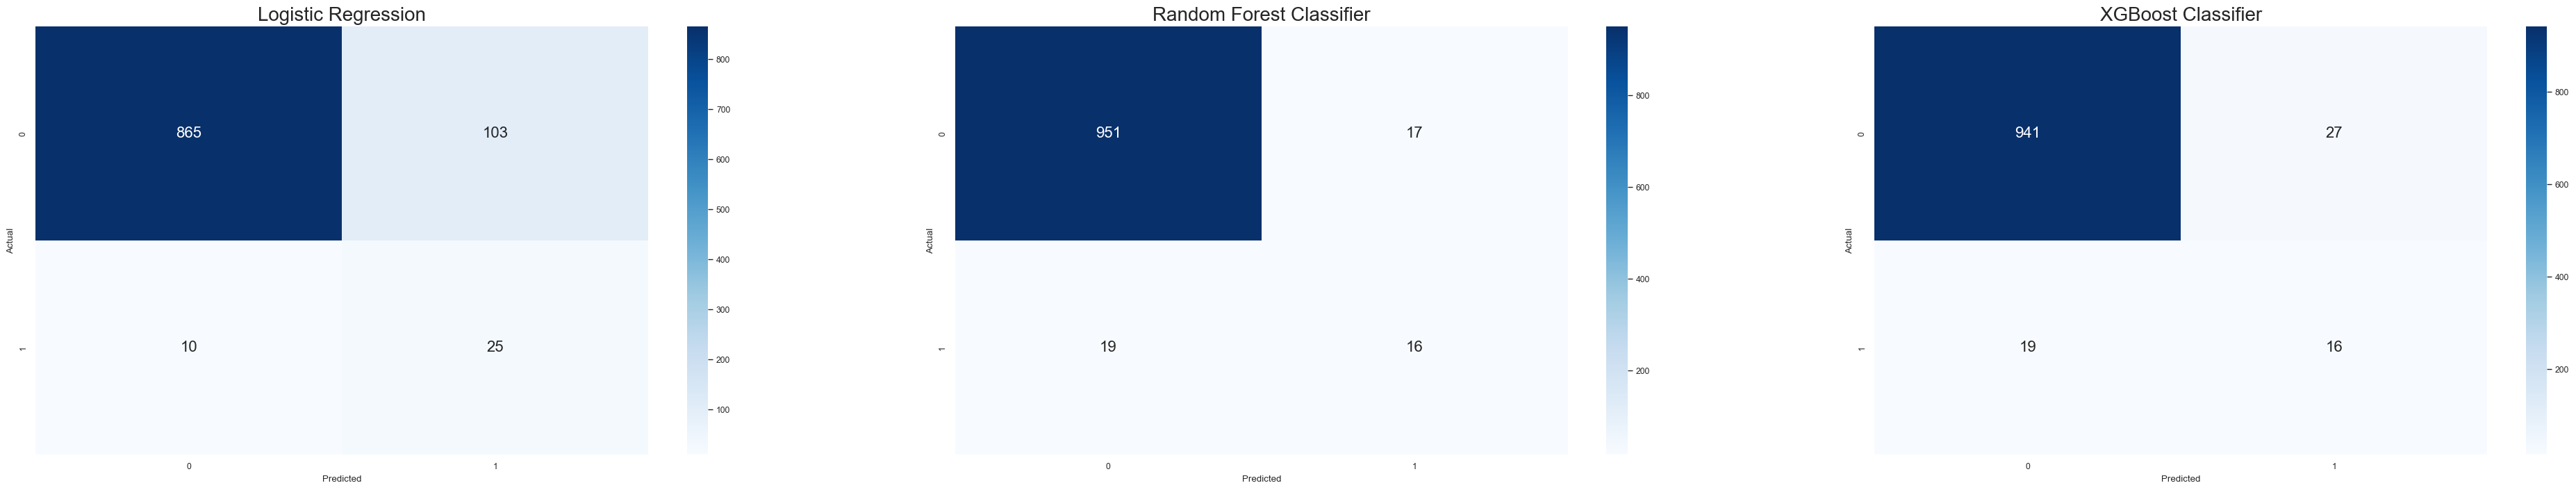

In [167]:
# Plotting confusion matrix for each classifier

conf_mx0 = confusion_matrix(y_val_sm,pred_reg_sm)
conf_mx1 = confusion_matrix(y_val_sm,smote_prediction_rfc)
conf_mx2 = confusion_matrix(y_val_sm,smote_prediction_xgb)
#conf_mx3 = confusion_matrix(y_val_sm,smote_prediction_cat)

heat_cm0 = pd.DataFrame(conf_mx0, columns=np.unique(y_val_sm), index = np.unique(y_val_sm))
heat_cm0.index.name = 'Actual'
heat_cm0.columns.name = 'Predicted'

heat_cm1 = pd.DataFrame(conf_mx1, columns=np.unique(y_val_sm), index = np.unique(y_val_sm))
heat_cm1.index.name = 'Actual'
heat_cm1.columns.name = 'Predicted'

heat_cm2 = pd.DataFrame(conf_mx2, columns=np.unique(y_val_sm), index = np.unique(y_val_sm))
heat_cm2.index.name = 'Actual'
heat_cm2.columns.name = 'Predicted'

#heat_cm3 = pd.DataFrame(conf_mx3, columns=np.unique(y_val_sm), index = np.unique(y_val_sm))
#heat_cm3.index.name = 'Actual'
#heat_cm3.columns.name = 'Predicted'

f, ax = plt.subplots(1, 3, figsize=(20,8))
f.subplots_adjust(left=None, bottom=None, right= 2, top=None, wspace=None, hspace= None)

sns.heatmap(heat_cm0, cmap="Blues", annot=True, annot_kws={"size": 16},fmt='g', ax = ax[0])
ax[0].set_title('Logistic Regression', fontsize = 20)
sns.heatmap(heat_cm1, cmap="Blues", annot=True, annot_kws={"size": 16},fmt='g', ax = ax[1])
ax[1].set_title('Random Forest Classifier', fontsize = 20)
sns.heatmap(heat_cm2, cmap="Blues", annot=True, annot_kws={"size": 16},fmt='g', ax = ax[2])
ax[2].set_title('XGBoost Classifier', fontsize = 20)
#sns.heatmap(heat_cm3, cmap="Blues", annot=True, annot_kws={"size": 16},fmt='g', ax = ax[3])
#ax[3].set_title('Catboot Classifier', fontsize = 20)

plt.show()

## Interpretation

#### Counts pulled from the plots
- Logistic Regression: TN=865, FP=103, FN=10, TP=25
- Random Forest: TN=951, FP=17, FN=19, TP=16
- XGBoost: TN=941, FP=27, FN=19, TP=16

#### Metrics implied by those counts
- Logistic Regression -> Precision = 15/(15+103) = 0.195; Recall = 25/35 = 0.714; F1 = 0.306; FPR = 103/968 = 10.6%; Accuracy = 0.887
    - Interpretation: catches most positives (25/35) but generates many false alarms (103 FP). Good if missing a positive is very costly and analysts can handle lots of reviews
- Random Forest -> Precision = 16/(16+17) = 0.485; Recall = 16/35 = 0.457; F1 = 0.469; FPR = 17/968 = 1.8%; Accuracy = 0.964
    - Interpretation: much fewer false positives with the best precision here, but it misses more positives (FN=19). Best when false positives are expensive
- XGBoost -> Precision = 16/(16+27) = 0.372; Recall = 16/35 = 0.457; F1 = 0.412; FPR = 27/968 = 2.8%; Accuracy = 0.954
    - Interpretation: similar recall to RF but more false positives and lower precision. At 0.5, it's dominated by RF on this split
 
#### Takeaways
- These matrices reflect one operating point (threshold=0.5). Changing the threshold slides each model along its precision-recall trade-off
- With a base rate=3.5%, LR's 128 predicted positives (25 TP + 103 FP) is a broad net; RF's 33 (16 TP + 17 FP) is a tighter net; XGB's 43 sits between but still less precise than RF
- Given our earlier ROC/PR results (RF AUC=0.92, PR AUC=0.50), the RF is the strongest ranker; choose a threshold to meet our cost constraints

## SVM

In [181]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

sss = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

pipe_lin = imbalanced_make_pipeline(
    StandardScaler(), # scale first (critical for SVM)
    SMOTE(sampling_strategy='minority'),
    LinearSVC(dual='auto', random_state=42)
)

param_dist_lin = {
    'linearsvc__C': np.logspace(-3, 2, 20),
    'linearsvc__class_weight': [None, 'balanced']
}

search_lin = RandomizedSearchCV(
    pipe_lin, 
    param_distributions=param_dist_lin, 
    n_iter=25, 
    scoring='average_precision',
    cv=sss,
    n_jobs=-1,
    random_state=42,
    refit=True
)

search_lin.fit(X_train_sm, y_train_sm)
svm_lin = search_lin.best_estimator_

/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1237: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1237: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1237: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1237: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1237: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1237: ConvergenceWarning: Liblinear failed to converge, increase the n

In [183]:
# Scores (continuous) for ROC/PR - threshold 0 is the standard SVM cutoff
scores_lin = svm_lin.decision_function(X_val_sm)
yhat_lin_0 = (scores_lin >= 0).astype(int)

print("Linear SVM - holdout")
print("ROC AUC: ", roc_auc_score(y_val_sm, scores_lin))
print("PR AUC:", average_precision_score(y_val_sm, scores_lin))
print(classification_report(y_val_sm, yhat_lin_0,
                            target_names=['Fin.Stable','Fin.Unstable'], digits=3))

# Pick a better threshold (maximize F1 or target precision)
p, r, thr = precision_recall_curve(y_val_sm, scores_lin)
f1 = 2*p*r/(p+r+1e-12)
thr_f1 = thr[np.nanargmax(f1)]
yhat_lin_f1 = (scores_lin >= thr_f1).astype(int)
print("\nLinear SVM @F1-opt threshold:", thr_f1)
print(classification_report(y_val_sm, yhat_lin_f1, target_names=['Fin.Stable','Fin.Unstable'], digits=3))

Linear SVM - holdout
ROC AUC:  0.8664108618654073
PR AUC: 0.4093674657812201
              precision    recall  f1-score   support

  Fin.Stable      0.990     0.856     0.919       968
Fin.Unstable      0.163     0.771     0.269        35

    accuracy                          0.853      1003
   macro avg      0.577     0.814     0.594      1003
weighted avg      0.962     0.853     0.896      1003


Linear SVM @F1-opt threshold: 0.9752349009393694
              precision    recall  f1-score   support

  Fin.Stable      0.977     0.991     0.984       968
Fin.Unstable      0.571     0.343     0.429        35

    accuracy                          0.968      1003
   macro avg      0.774     0.667     0.706      1003
weighted avg      0.962     0.968     0.964      1003



## Interpretation

#### Ranking quality (threshold-free)
- ROC AUC = 0.866 - good separation, but below RF (0.92) and XGB (0.91)
- PR AUC = 0.409 - ~11-12x the base rate (3.5%), but below RF (0.50) and below our tuned LR )0.45)
- Overview: as a ranker, Linear SVM trails RF/XGB on this data

#### At the default SVM cutoff (score >= 0)
- TP = 27, FN = 9
- FP = 139, TN = 829 -> FPR = 14.4%
- Overview: very high recall but lots of false alarms (precision ~16%). Accuracy looks low because FPs are heavy

#### At our F1-optimal threshold (0.975 on the decision function)
- TP = 12, FN = 23
- FP = 9, TN = 959 -> FPR = 0.9%
- Overview: raising the threshold slashes false positives (precision up to ~57%, accuracy up), but recall drops to ~34% (we miss more positives)
    - The big shift in threshold (0.975) is normal for SVM's decision_function - it's not a probability. If we need probabilities, calibrate (Platt/isotonic)
 
#### Hot it stacks up 
- Random Forest remains the best overall: higher ROC/PR AUC and nicer precision-recall trade-off at practical thresholds
- Linear SVM can mimic LR: high-recall/low-precision at default, and useable precision only after pushing the threshold (with recall loss)

## Naïve Bayes model

In [187]:
from sklearn.naive_bayes import GaussianNB

# 5-fold stratified CV (same as your other models)
sss = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Pipeline: SMOTE only on training folds + GaussianNB
pipe_gnb = imbalanced_make_pipeline(
    SMOTE(sampling_strategy="minority"),
    GaussianNB()
)

# Only real hyperparameter for GNB
param_dist_gnb = {
    "gaussiannb__var_smoothing": np.logspace(-12, -6, 30)  # numeric stability
}

search_gnb = RandomizedSearchCV(
    pipe_gnb,
    param_distributions=param_dist_gnb,
    n_iter=25,
    scoring="average_precision",   # PR-AUC for imbalance
    cv=sss,
    n_jobs=-1,
    random_state=42,
    refit=True
)

# Fit on train, evaluate on untouched holdout
search_gnb.fit(X_train_sm, y_train_sm)
nb = search_gnb.best_estimator_

y_pred   = nb.predict(X_val_sm)
y_scores = nb.predict_proba(X_val_sm)[:, 1]    # NB gives probabilities

print("GaussianNB — holdout")
print("ROC AUC:", roc_auc_score(y_val_sm, y_scores))
print("PR  AUC:", average_precision_score(y_val_sm, y_scores))
print(classification_report(y_val_sm, y_pred,
                            target_names=["Fin.Stable","Fin.Unstable"], digits=3))

# Optional: choose a better operating point (e.g., maximize F1)
p, r, thr = precision_recall_curve(y_val_sm, y_scores)
f1 = 2*p*r/(p+r+1e-12)
t_f1 = thr[np.nanargmax(f1)]
y_pred_f1 = (y_scores >= t_f1).astype(int)
print("\nGaussianNB @F1-opt threshold:", t_f1)
print(classification_report(y_val_sm, y_pred_f1,
                            target_names=["Fin.Stable","Fin.Unstable"], digits=3))

GaussianNB — holdout
ROC AUC: 0.7693476977567888
PR  AUC: 0.22721910676580126
              precision    recall  f1-score   support

  Fin.Stable      0.988     0.653     0.786       968
Fin.Unstable      0.074     0.771     0.136        35

    accuracy                          0.657      1003
   macro avg      0.531     0.712     0.461      1003
weighted avg      0.956     0.657     0.763      1003


GaussianNB @F1-opt threshold: 0.9999999999999716
              precision    recall  f1-score   support

  Fin.Stable      0.980     0.969     0.975       968
Fin.Unstable      0.348     0.457     0.395        35

    accuracy                          0.951      1003
   macro avg      0.664     0.713     0.685      1003
weighted avg      0.958     0.951     0.954      1003



## Interpretation

#### Threshold-free quality
- ROC AUC = 0.769 and PR AUC = 0.227 -> this is well below our RF (~0.92/0.50), XGB (~0.91/~0.50), LR (~0.87/~0.45), and Linear SVM (~0.87/~0.41) -> as a ranker, GNB is the weakest so far.

#### At the default decision rule (predict, =0.5)
- TP = 27, FN = 8, FP = 337, TN = 631 -> FPR = 34.8%
    - Interpretation: very high recall but floods with false positives; precision collapses to ~7%
 
#### At the F1-optimal threshold (~0.99999999999997)
- TP = 16, FN = 19, FP = 30, TN = 938 -> FPR = 3.1%
    - Interpretation: tuning the threshold makes it usable (precision up, FPR down), but it lags Random Forest (0.45 precision, 0.51 recall at 0.5)
 
#### Why the behavior?
- Naive Bayes assumptions (Gaussian per feature, conditional independence) likely don't hold; many numeric features are correlated
- With many features, GNB multiplies likelihoods -> extreme, poorly calibrated posteriors, hence the near-1 optimal threshold
- SMOTE can shirnk/fit variances and further distort the Gaussian assumption

#### Bottom Line
GNB gives high recall at default but overwhelms with false positives; after thresholding it's respectable but still dominated by Random Forest / XGB on both PR AUC and practical operating points. Keep RF as your champion; use GNB only if you need a very fast, simple model or as a diverse component in an ensemble

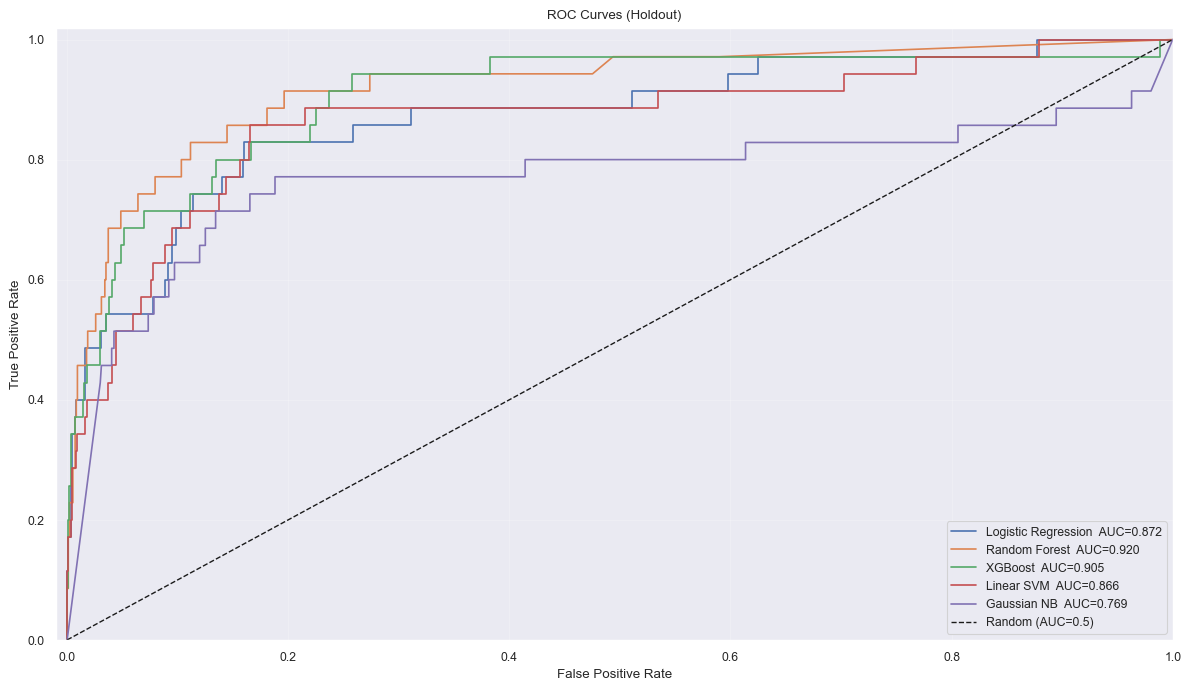

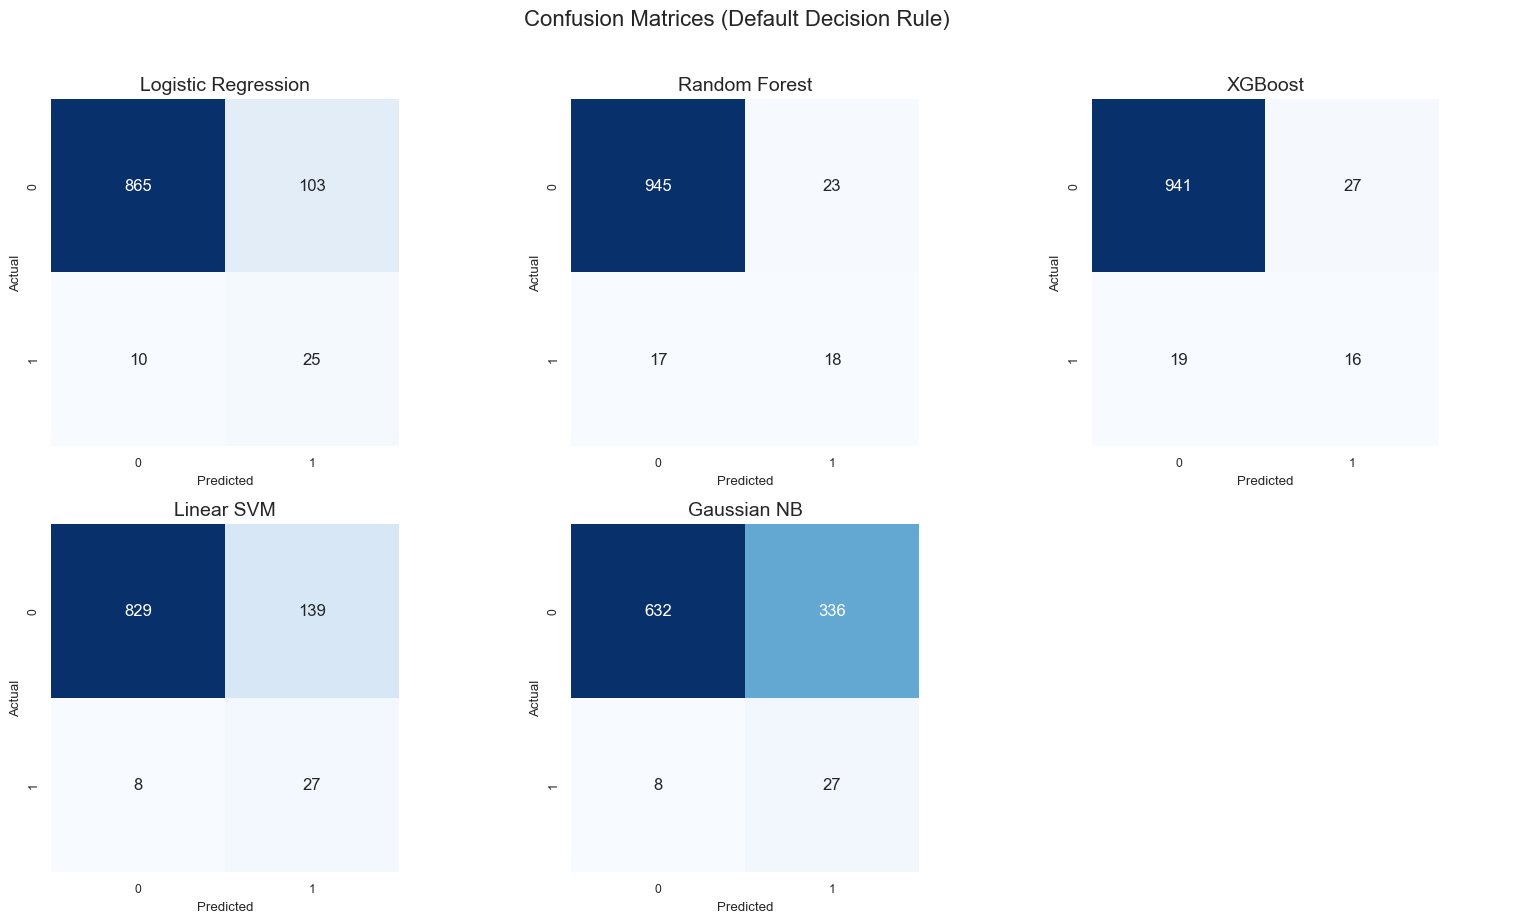


Logistic Regression
ROC AUC: 0.872491145218418
PR  AUC: 0.45339853408830993
              precision    recall  f1-score   support

  Fin.Stable      0.989     0.894     0.939       968
Fin.Unstable      0.195     0.714     0.307        35

    accuracy                          0.887      1003
   macro avg      0.592     0.804     0.623      1003
weighted avg      0.961     0.887     0.917      1003


Random Forest
ROC AUC: 0.920439787485242
PR  AUC: 0.5026024904980773
              precision    recall  f1-score   support

  Fin.Stable      0.982     0.977     0.980       968
Fin.Unstable      0.450     0.514     0.480        35

    accuracy                          0.961      1003
   macro avg      0.716     0.746     0.730      1003
weighted avg      0.964     0.961     0.962      1003


XGBoost
ROC AUC: 0.9053719008264463
PR  AUC: 0.4817134720876405
              precision    recall  f1-score   support

  Fin.Stable      0.980     0.972     0.976       968
Fin.Unstable      0.372  

In [190]:
#import numpy as np
#import pandas as pd
#import matplotlib.pyplot as plt
#import seaborn as sns

#from sklearn.metrics import (
#    roc_curve, roc_auc_score,
#    precision_recall_curve, average_precision_score,
#    confusion_matrix, classification_report
#)

# ----------------------------
# 1) Collect models and scores
# ----------------------------
models = {
    "Logistic Regression": best_est_reg,
    "Random Forest":       final_model,
    "XGBoost":             best_est_xgb,
    "Linear SVM":          svm_lin,     # uses decision_function
    "Gaussian NB":         nb
}

def get_scores(model, X):
    """Return continuous scores for ROC/PR (probs if available; else decision_function; else labels)."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    if hasattr(model, "decision_function"):
        return model.decision_function(X)
    # last resort (not ideal for ROC/PR, but keeps things running)
    return model.predict(X)

scores = {name: get_scores(m, X_val_sm) for name, m in models.items()}

# ----------------------------
# 2) ROC curve (all models)
# ----------------------------
plt.figure(figsize=(12, 7))
for name, s in scores.items():
    fpr, tpr, _ = roc_curve(y_val_sm, s)
    auc = roc_auc_score(y_val_sm, s)
    plt.plot(fpr, tpr, label=f"{name}  AUC={auc:.3f}")

plt.plot([0, 1], [0, 1], "k--", lw=1, label="Random (AUC=0.5)")
plt.xlim(-0.01, 1.0); plt.ylim(0.0, 1.02)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves (Holdout)")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

# -----------------------------------------
# 3) Confusion matrices at default threshold
# -----------------------------------------
def predict_default(model, s):
    """
    Convert scores to class predictions using the model's default rule:
    - If model has .predict_proba (threshold 0.5), rely on .predict()
    - If model is an SVM (decision_function), .predict() uses threshold 0.0
    """
    return model.predict(X_val_sm)

cm_results = {}
for name, mdl in models.items():
    yhat = predict_default(mdl, scores[name])
    cm = confusion_matrix(y_val_sm, yhat, labels=[0, 1])
    cm_results[name] = cm

# Plot heatmaps (2x3 grid; last cell hidden)
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()

for ax, (name, cm) in zip(axes, cm_results.items()):
    df_cm = pd.DataFrame(cm, index=[0,1], columns=[0,1])
    sns.heatmap(df_cm, cmap="Blues", annot=True, fmt="g",
                cbar=False, square=True, ax=ax,
                annot_kws={"size": 12})
    ax.set_title(name, fontsize=14)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")

# Hide any unused subplot (in case of fewer than 6)
if len(cm_results) < len(axes):
    for j in range(len(cm_results), len(axes)):
        axes[j].axis("off")

plt.suptitle("Confusion Matrices (Default Decision Rule)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Print quick metrics beside the confusion mats
# ---------------------------------------------------------
for name, mdl in models.items():
    yhat = mdl.predict(X_val_sm)
    s = scores[name]
    print(f"\n{name}")
    print("ROC AUC:", roc_auc_score(y_val_sm, s))
    print("PR  AUC:", average_precision_score(y_val_sm, s))
    print(classification_report(
        y_val_sm, yhat, target_names=["Fin.Stable","Fin.Unstable"], digits=3
    ))

# ---------------------------------------------------------
# (Optional) If you want F1-opt threshold confusion matrices
# ---------------------------------------------------------
# Example for Random Forest (repeat for others if desired):
# from sklearn.metrics import f1_score
# p, r, thr = precision_recall_curve(y_val_sm, scores["Random Forest"])
# f1 = 2*p*r/(p+r+1e-12)
# t_f1 = thr[np.nanargmax(f1)]
# yhat_rf_f1 = (scores["Random Forest"] >= t_f1).astype(int)
# print("\nRandom Forest @F1-opt threshold:", t_f1)
# print(confusion_matrix(y_val_sm, yhat_rf_f1, labels=[0,1]))
